# Predicting Churn and Identifying High-Risk Individuals Among HorizonTel Communications Customers

## GitHub Link
### https://github.com/jharrison4386/ADS-505-Group-8-Project

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#%pip install plotnine
#%pip install kmodes
from plotnine import *
import plotnine
from kmodes.kprototypes import KPrototypes
import warnings
warnings.filterwarnings('ignore', category = FutureWarning)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.metrics import silhouette_score
import mlba

 Disclaimer: The data set was originally an IBM test set (TanKY, n.d.) used for training purposes (Telco Customer Churn (11.1.3+), n.d.), so we chose to place the data set in the context of a fictional telecommunications company called HorizonTel Communications.

# Problem Statement

HorizonTel Communications is interested in utilizing its in-house data to identify customers who are at risk of churning and understanding the factors that influence customer retention. Customer churn can negatively impact revenue, increase customer acquisition costs, and hinder long-term business growth. Without a full-scope approach to identifying at risk customers and understanding their distinct needs, retention efforts may be inefficient and fail to address the underlying causes of customer dissatisfaction.

This project aims to develop a data-driven approach to customer retention by combining predictive modeling and customer segmentation. First, classification models will be developed to predict customer churn and identify customer characteristics and service related factors associated with an increased likelihood of leaving. Second, clustering techniques will be applied to develop distinct customer profiles based on relevant demographic, account, service usage, and billing characteristics. These profiles will help HorizonTel Communications understand differences in customer behavior, identify segments that may require targeted intervention, and fomrulate tailored retention strategies.



# Data Description

The dataset used in this project contains customer-level information from an IBM test set used for training purposes. The dataset includes 7,043 observations and 33 features, with each observation representing an individual customer. The data provides information about customer demographics, account characteristics, subscribed services, billing information, and churn status.

The dataset contains a combination of numerical and categorical variables. Numerical variables include Tenure Months, Monthly Charges, and Total Charges, which describe measurable account characteristics. Categorical variables include Gender, Senior Citizen, Internet Service, and Payment method, which represent customer attributes and service selections. The target variable, Churn Value, indicates whether a customer has discontinued services with HorizonTel Communications. This variable will serve as the target for supervised classification models designed to estimate customer churn likelihood.

Prior to modeling, exploratory data analysis was conducted to assess the dataset's structure, data types, completeness, and overall quality. The analysis identified 5,174 missing values in one variable, Churn Reason. Values that were missing were from customers who had not churned. Since they were still with HorizonTel Communications, no Churn Reason was recorded. No duplicate records are present in the dataset. Additionally, the dataset was reviewed for variables requiring preprocessing before analysis.

The distribution of churn was examined to understand the prevalence of customers leaving. Of the 7,043 customers, 1,869 churned, corresponding to a churn rate of 26.54%. The remaining 5,174 customers were classified as non-churned. The distribution is important for evaluating classification performance, as an imbalance between churned and non-churned customers may affect model training.

# Data Quality

In [ ]:
# Load in data
df = pd.read_excel('Telco_customer_churn.xlsx')

In [ ]:
# View missing values
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [ ]:
# Check churn value counts
df['Churn Value'].value_counts()

Churn Value
0    5174
1    1869
Name: count, dtype: int64

Data is clean with only missing values being located in Churn Reason. These values are missing for customers who have not churned. The churn class is heavily imbalanced, with only 26.54% of customers churning.

In [ ]:
print(df.dtypes)

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges         object
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object


In [ ]:
# Check for duplicate customers
df['CustomerID'].duplicated().sum()

np.int64(0)

In [ ]:
df['Total Charges'].describe()

count    7043.000
unique   6531.000
top        20.200
freq       11.000
Name: Total Charges, dtype: float64

In [ ]:
# Check Total Charges to see if it should actually be object
df['Total Charges'].head(50).values

array([108.15, 151.65, 820.5, 3046.05, 5036.3, 528.35, 39.65, 20.15,
       4749.15, 30.2, 1093.1, 316.9, 3549.25, 1105.4, 144.15, 1426.4,
       633.3, 1752.55, 857.25, 79.35, 496.9, 927.35, 113.85, 2514.5,
       7611.85, 5238.9, 2868.15, 1064.65, 229.55, 2135.5, 1502.65, 35.45,
       81.25, 70.45, 563.65, 45.65, 655.5, 1592.35, 273, 2651.2, 242.8,
       5000.2, 1145.7, 503.6, 29.95, 662.65, 1111.65, 24.8, 531, 79.9],
      dtype=object)

Based on these values, Total Charges should be a numeric column rather than an object.

In [ ]:
# Convert Total Charges to be numeric instead of object, fill resulting na from blank string with 0
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
df['Total Charges'] = df['Total Charges'].fillna(0)

In [ ]:
# Check unique values per column
print(df.nunique())

CustomerID           7043
Count                   1
Country                 1
State                   1
City                 1129
Zip Code             1652
Lat Long             1652
Latitude             1652
Longitude            1651
Gender                  2
Senior Citizen          2
Partner                 2
Dependents              2
Tenure Months          73
Phone Service           2
Multiple Lines          3
Internet Service        3
Online Security         3
Online Backup           3
Device Protection       3
Tech Support            3
Streaming TV            3
Streaming Movies        3
Contract                3
Paperless Billing       2
Payment Method          4
Monthly Charges      1585
Total Charges        6531
Churn Label             2
Churn Value             2
Churn Score            85
CLTV                 3438
Churn Reason           20
dtype: int64


In [ ]:
# Look at categorical unique values
categorical_cols = [
    'Gender',
    'Senior Citizen',
    'Partner',
    'Dependents',
    'Phone Service',
    'Multiple Lines',
    'Internet Service',
    'Online Security',
    'Online Backup',
    'Device Protection',
    'Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Contract',
    'Paperless Billing',
    'Payment Method',
]

numeric_cols = ['Tenure Months', 'Total Charges', 'Monthly Charges']

for col in categorical_cols:
    print(f'\n--- {col} ---')
    print(df[col].unique())


--- Gender ---
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

--- Senior Citizen ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- Partner ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- Dependents ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- Phone Service ---
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

--- Multiple Lines ---
<StringArray>
['No', 'Yes', 'No phone service']
Length: 3, dtype: str

--- Internet Service ---
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

--- Online Security ---
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

--- Online Backup ---
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

--- Device Protection ---
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

--- Tech Support ---
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

--- Streaming TV ---
<StringArray>
['No', 'Yes', 'No internet service'

In [ ]:
for col in categorical_cols:
    print(f'\n--- {col} ---')
    print(df[col].value_counts(dropna=False))


--- Gender ---
Gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Senior Citizen ---
Senior Citizen
No     5901
Yes    1142
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     5416
Yes    1627
Name: count, dtype: int64

--- Phone Service ---
Phone Service
Yes    6361
No      682
Name: count, dtype: int64

--- Multiple Lines ---
Multiple Lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- Internet Service ---
Internet Service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- Online Security ---
Online Security
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- Online Backup ---
Online Backup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

--- Device Protection

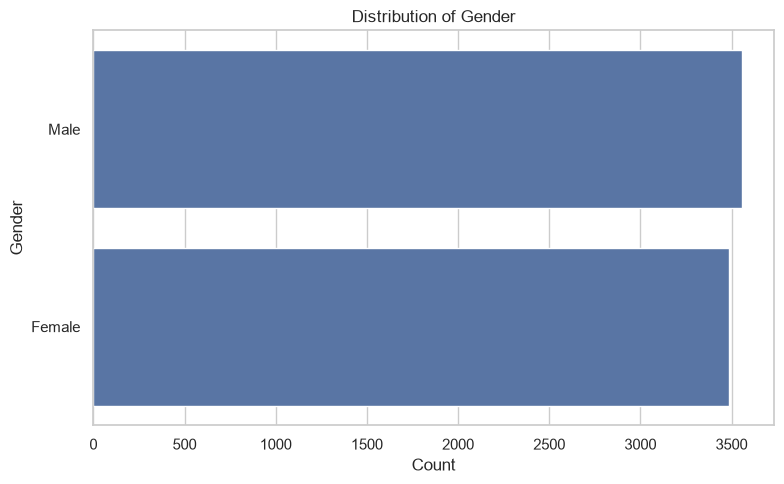

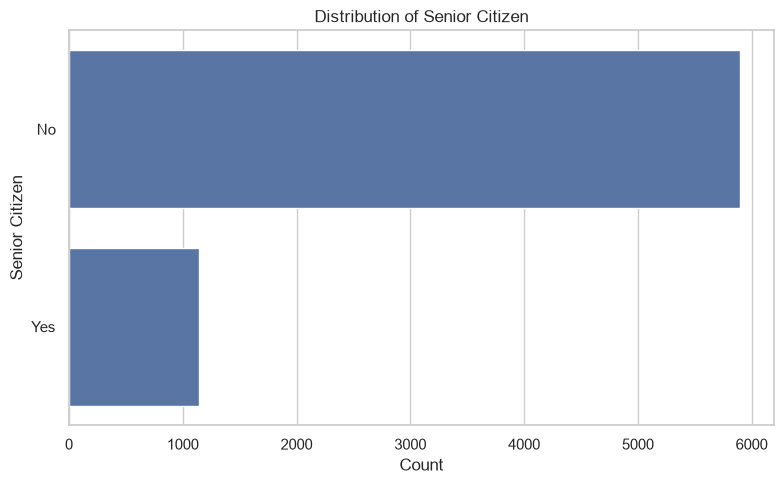

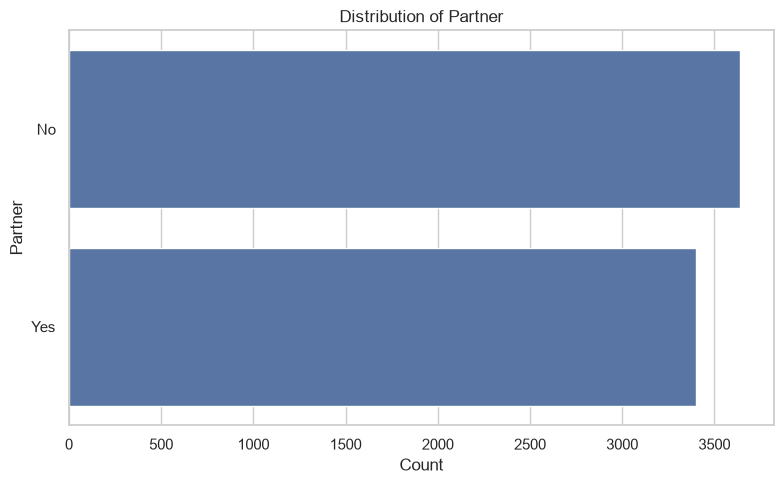

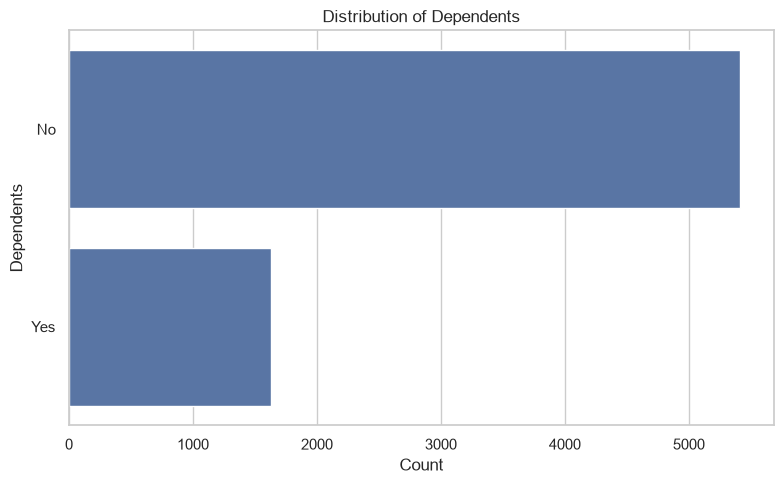

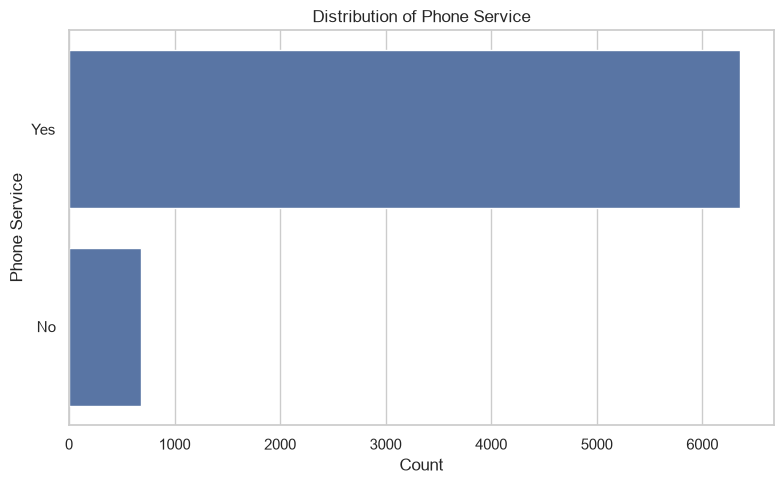

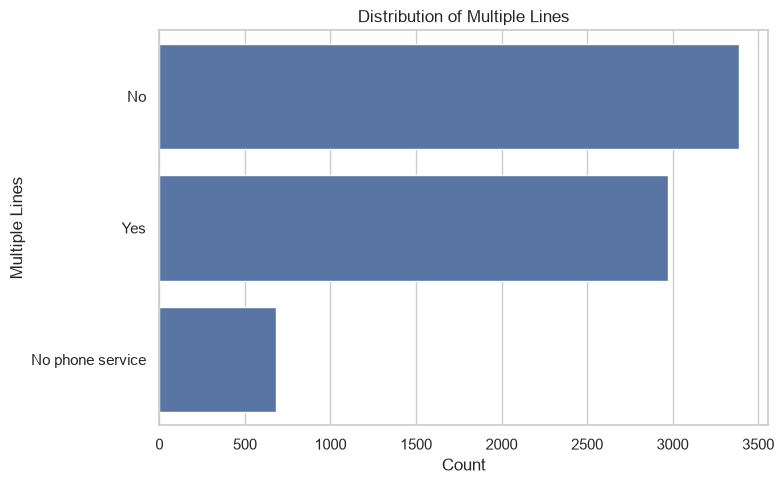

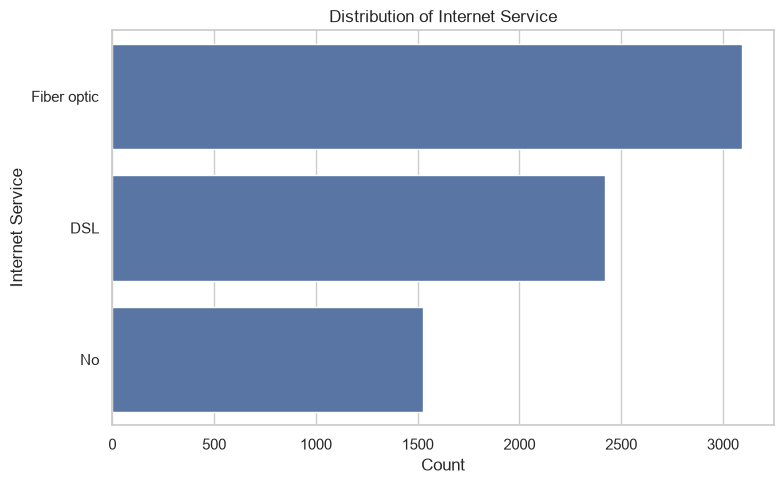

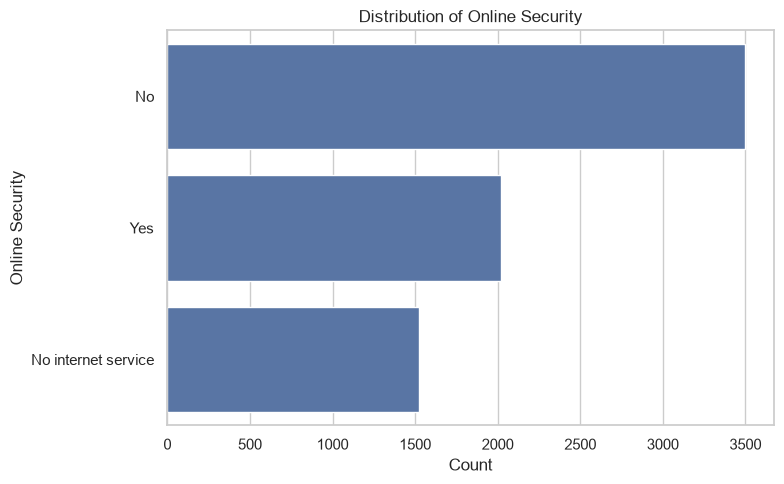

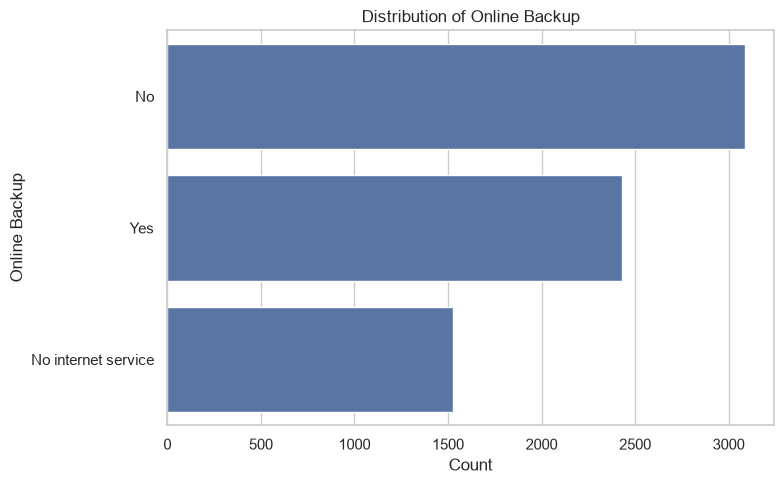

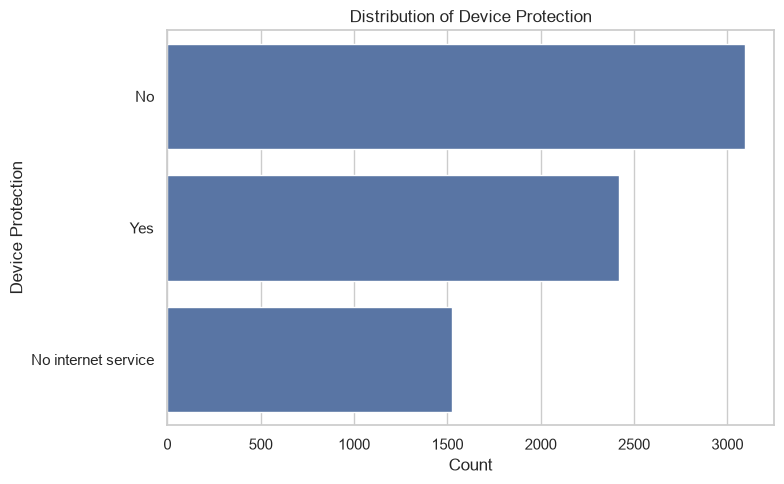

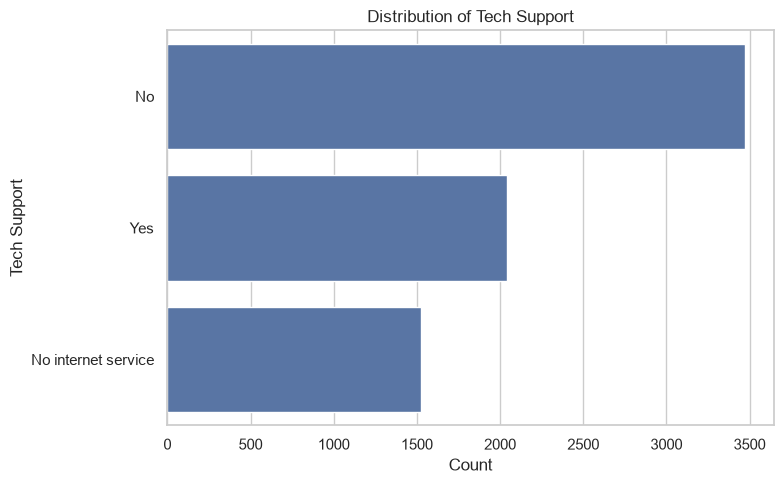

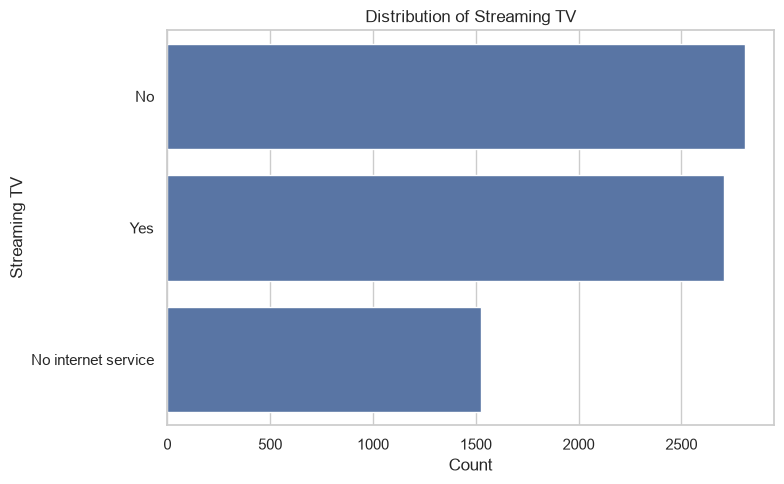

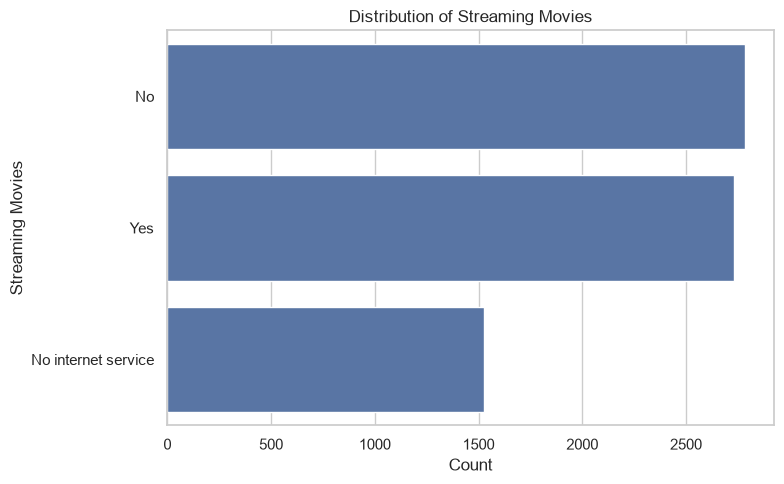

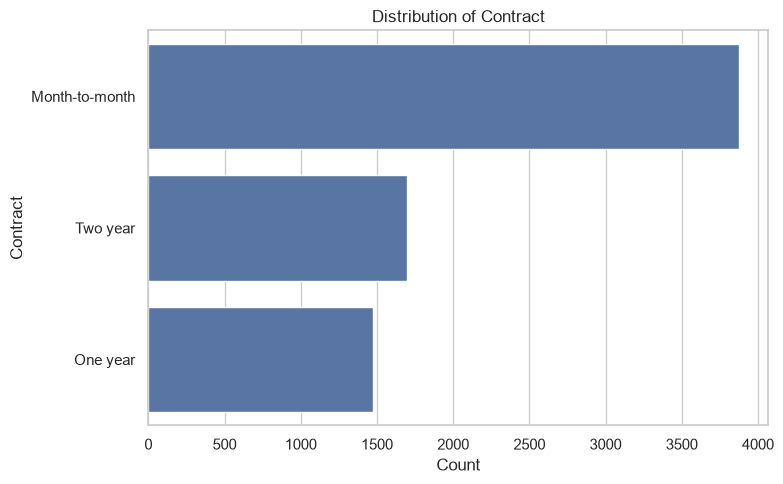

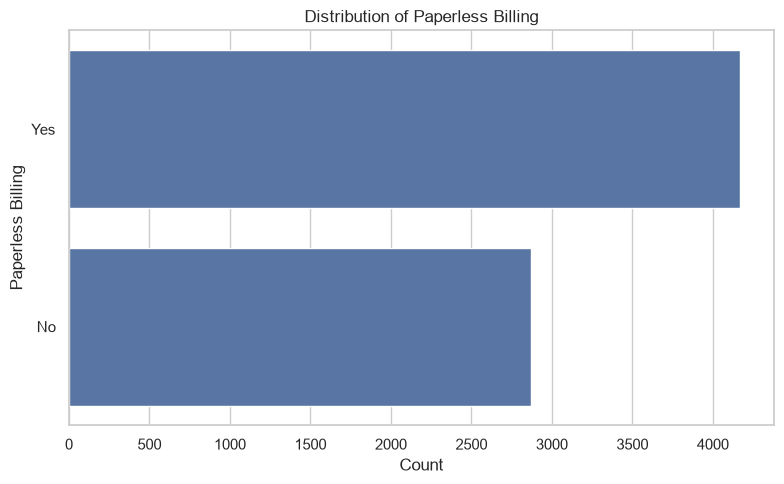

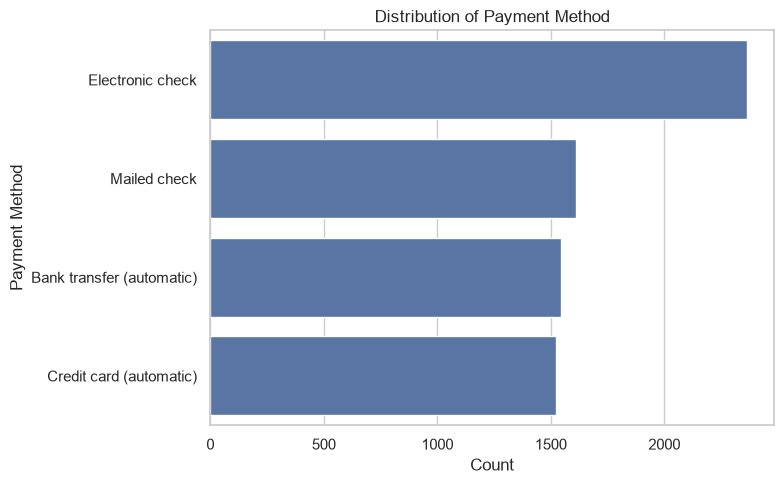

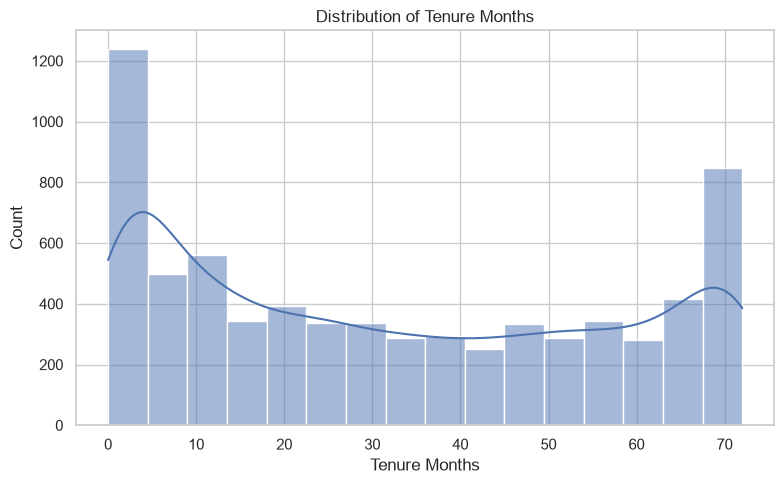

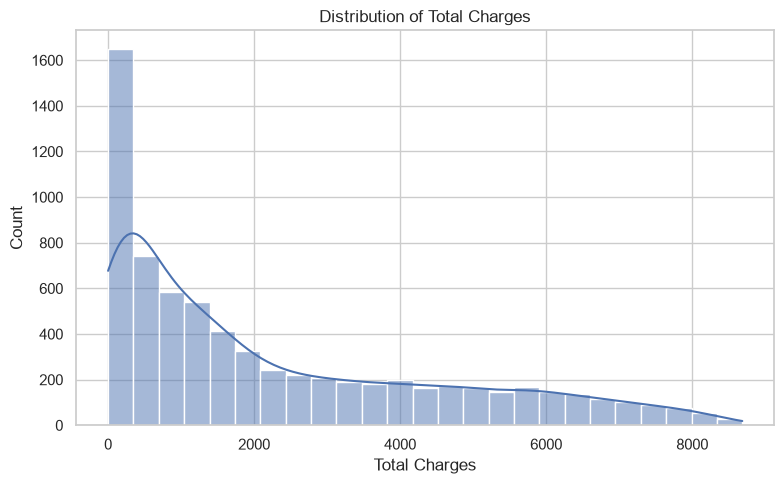

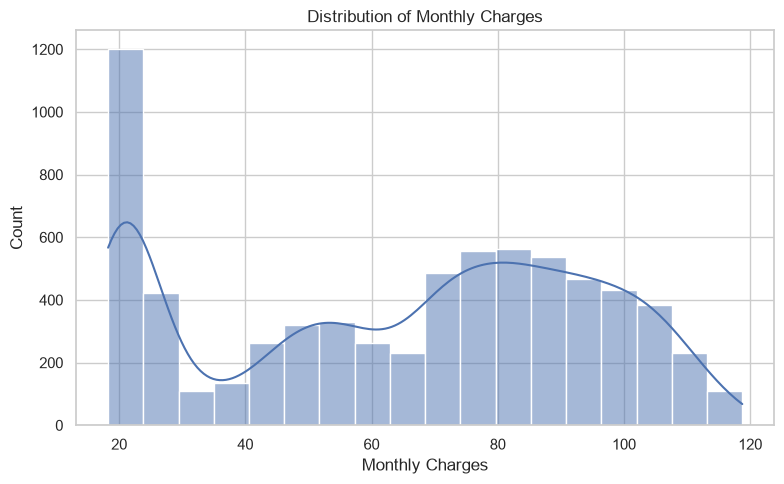

In [ ]:
# Plot every column to view distributions
for col in df[categorical_cols + numeric_cols].columns:

    # Skip columns with no data
    if df[col].dropna().empty:
        continue

    plt.figure(figsize=(8, 5))

    # Numeric columns
    if pd.api.types.is_numeric_dtype(df[col]):
        sns.histplot(df[col].dropna(), kde=True)
        plt.title(f'Distribution of {col}')
        plt.xlabel(col)
        plt.ylabel('Count')

    # Categorical columns
    else:
        # Get category counts
        counts = df[col].fillna('Missing').value_counts()

        # Limit extremely high-cardinality variables
        if len(counts) > 20:
            counts = counts.head(20)
            title = f'Top 20 Categories of {col}'
        else:
            title = f'Distribution of {col}'

        sns.barplot(x=counts.values, y=counts.index)
        plt.title(title)
        plt.xlabel('Count')
        plt.ylabel(col)

    plt.tight_layout()
    plt.show()

# Churn Distributions Investigation

In [ ]:
print(df['Churn Label'].value_counts())
print(f"\nPercentage of customers who churn: {100 * df['Churn Value'].mean():.2f}%")

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Percentage of customers who churn: 26.54%


## Customer Characteristics and Their Relation to Churn

In [ ]:
# Check churn rates and customer totals for cities
city_churn = (
    df.groupby('City')
      .agg(
          Customers=('Churn Value', 'size'),
          Churn_Rate=('Churn Value', 'mean')
      )
)

city_churn['Churn_Rate'] = city_churn['Churn_Rate'] * 100

city_churn = city_churn.sort_values(
    'Churn_Rate',
    ascending=False
)

print(city_churn[city_churn['Customers'] > 20].head(40))

                Customers  Churn_Rate
City                                 
Santa Rosa             24      45.833
Modesto                28      42.857
Santa Barbara          28      35.714
San Diego             150      33.333
Glendale               40      32.500
Torrance               25      32.000
Pasadena               30      30.000
San Francisco         104      29.808
Los Angeles           305      29.508
San Bernardino         28      28.571
Berkeley               32      28.125
Stockton               44      27.273
San Jose              112      25.893
Fresno                 64      25.000
Santa Ana              24      25.000
Anaheim                28      25.000
Riverside              32      25.000
Long Beach             60      25.000
Oakland                52      25.000
Sacramento            108      24.074
Burbank                25      24.000
Inglewood              25      20.000
Santa Monica           25      20.000
Chula Vista            25      20.000
Irvine      

Only 27/1129 cities have more than 20 customers located in them. Because of this, cities will probably not be reliable for predicting churn as the number of customers will be too low to rely on.

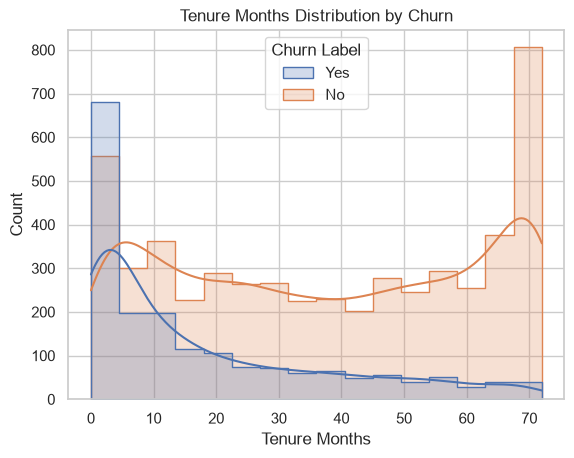

In [ ]:
sns.histplot(data=df, x='Tenure Months', hue='Churn Label',
             kde=True, element='step')
plt.title('Tenure Months Distribution by Churn')
plt.show()

Lower tenure months have a much higher churn rate for lower months, and a much lower churn rate at higher months

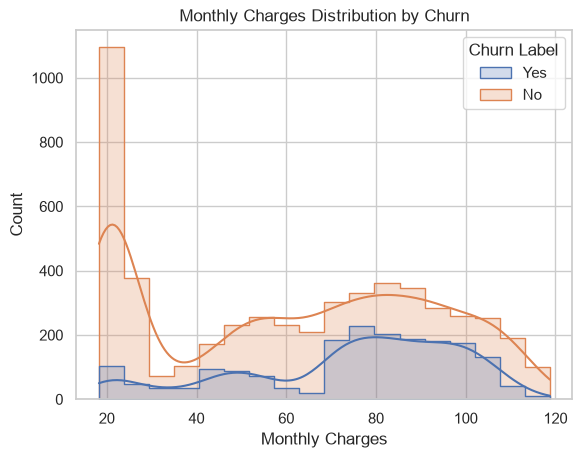

In [ ]:
sns.histplot(data=df, x='Monthly Charges', hue='Churn Label',
             kde=True, element='step')
plt.title('Monthly Charges Distribution by Churn')
plt.show()

Lower costs tend to have a lower churn rate

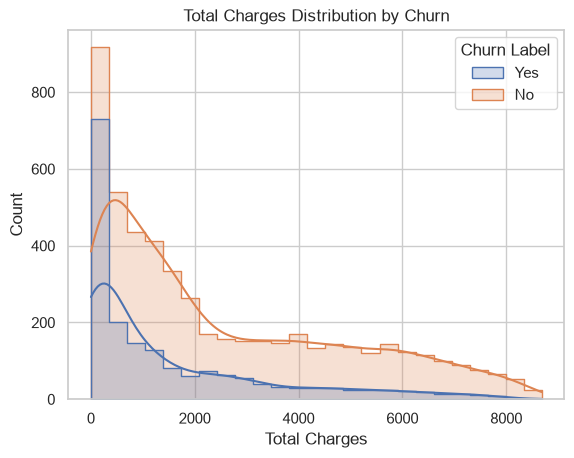

In [ ]:
sns.histplot(data=df, x='Total Charges', hue='Churn Label',
             kde=True, element='step')
plt.title('Total Charges Distribution by Churn')
plt.show()

Higher total charges has a lower churn rate, most likely due to a customer having stayed for longer already, showing loyalty.

c:\Users\mlmug\miniconda3\envs\py313\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.


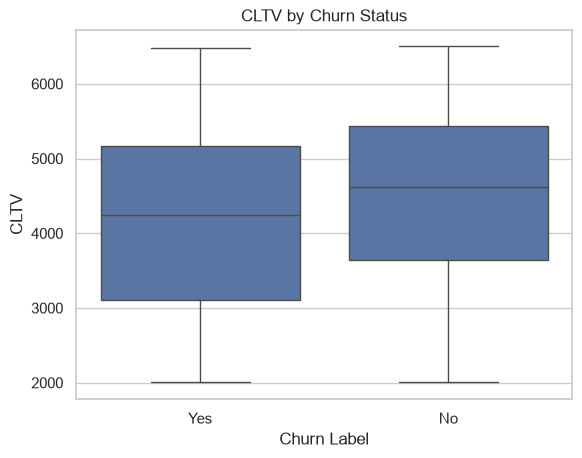

In [ ]:
sns.boxplot(data=df, x='Churn Label', y='CLTV')
plt.title('CLTV by Churn Status')
plt.show()

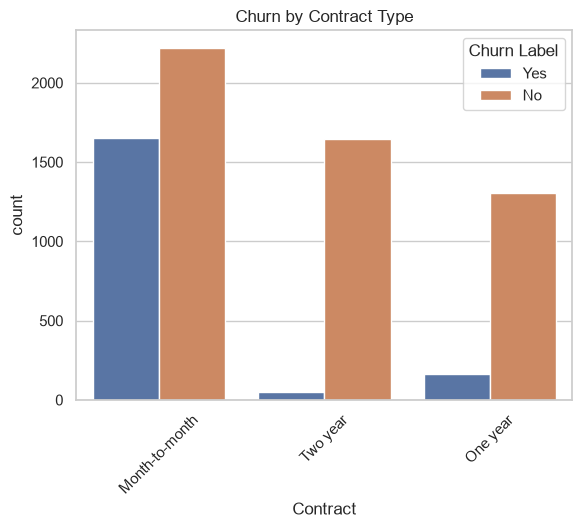

In [ ]:
sns.countplot(data=df, x='Contract', hue='Churn Label')
plt.title('Churn by Contract Type')
plt.xticks(rotation=45)
plt.show()

Month-to-month contract type has a much higher churn rate.
- Month-to-month churn rate: 42.71%
- One year churn rate: 11.27%
- Two year churn rate: 2.83%

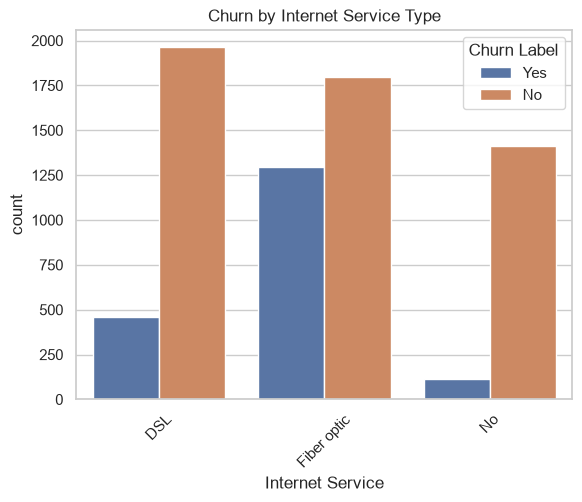

In [ ]:
sns.countplot(data=df, x='Internet Service', hue='Churn Label')
plt.title('Churn by Internet Service Type')
plt.xticks(rotation=45)
plt.show()

Fiber optic internet service type has much higher churn rate
- DSL churn rate: 18.96%
- Fiber optic churn rate: 41.89%
- No internet churn rate: 7.40%

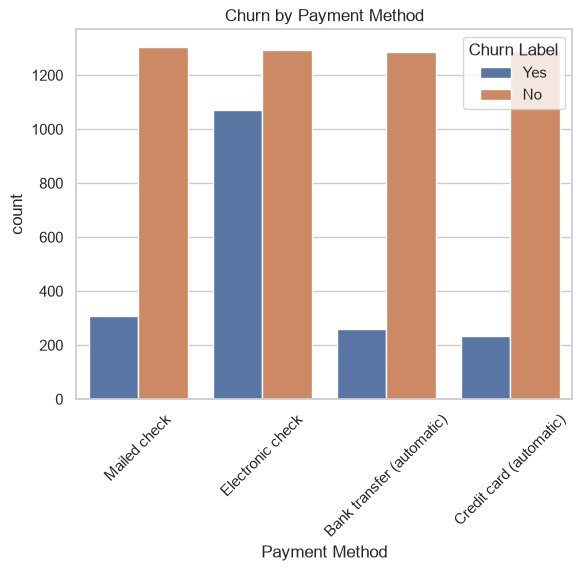

In [ ]:
sns.countplot(data=df, x='Payment Method', hue='Churn Label')
plt.title('Churn by Payment Method')
plt.xticks(rotation=45)
plt.show()

Electronic check has higher churn rate
- Mailed check churn rate: 19.11%
- Electronic check churn rate: 45.29%
- Bank transfer churn rate: 16.71%
- Credit card churn rate: 15.24%

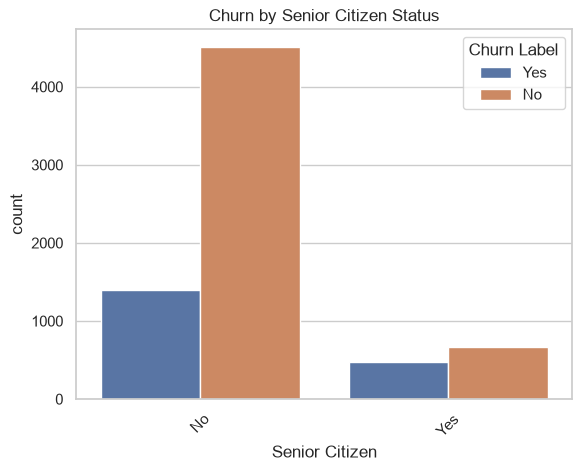

In [ ]:
sns.countplot(data=df, x='Senior Citizen', hue='Churn Label')
plt.title('Churn by Senior Citizen Status')
plt.xticks(rotation=45)
plt.show()

Senior citizens have a higher churn rate
- Not senior citizen churn rate: 23.61%
- Senior citizen churn rate: 41.68%

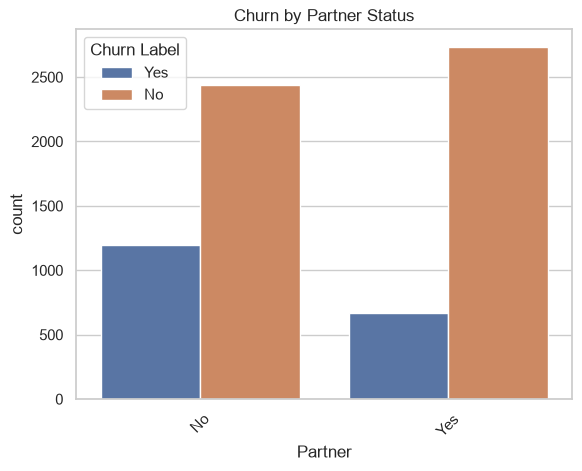

In [ ]:
sns.countplot(data=df, x='Partner', hue='Churn Label')
plt.title('Churn by Partner Status')
plt.xticks(rotation=45)
plt.show()

Customers without partners have a higher churn rate
- No partner churn rate: 32.96%
- Has partner churn rate: 19.66%

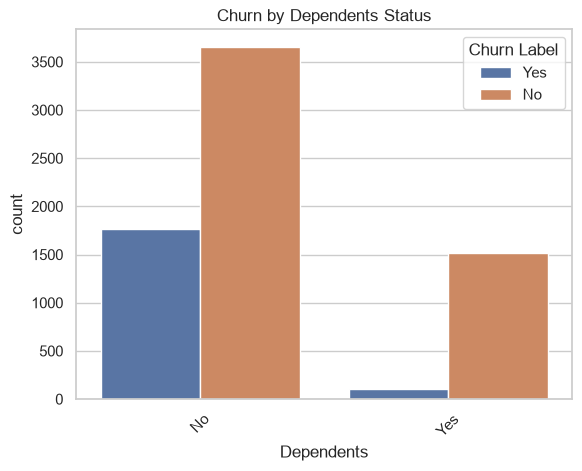

In [ ]:
sns.countplot(data=df, x='Dependents', hue='Churn Label')
plt.title('Churn by Dependents Status')
plt.xticks(rotation=45)
plt.show()

Customers with no dependents have a higher churn rate than those who do.
- No dependents churn rate: 32.55%
- Has dependents churn rate: 6.52%

## Services and Their Relation to Churn

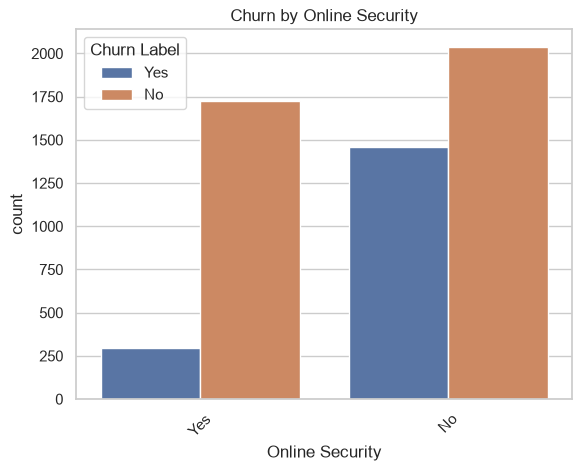

In [ ]:
sns.countplot(data=df[df['Online Security'] != 'No internet service'], x='Online Security', hue='Churn Label')
plt.title('Churn by Online Security')
plt.xticks(rotation=45)
plt.show()

Customers with no online security have a higher churn rate than those who do.
- No online security churn rate: 41.77%
- Has online security churn rate: 14.61%

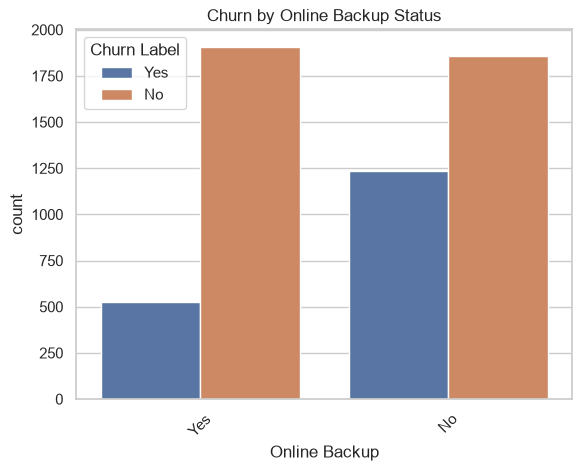

In [ ]:
sns.countplot(data=df[df['Online Backup'] != 'No internet service'], x='Online Backup', hue='Churn Label')
plt.title('Churn by Online Backup Status')
plt.xticks(rotation=45)
plt.show()

Customers with no online backup have a higher churn rate.
- No online backup churn rate: 39.93%
- Has online backup churn rate: 21.53%

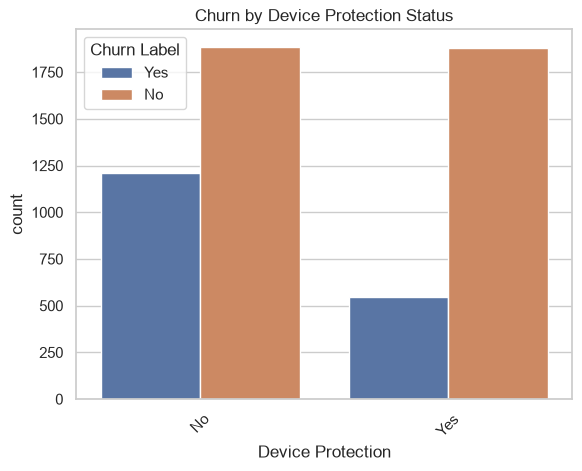

In [ ]:
sns.countplot(data=df[df['Device Protection'] != 'No internet service'], x='Device Protection', hue='Churn Label')
plt.title('Churn by Device Protection Status')
plt.xticks(rotation=45)
plt.show()

Customers with no device protection have a higher churn rate.
- No device protection churn rate: 39.13%
- Has device protection churn rate: 22.50%

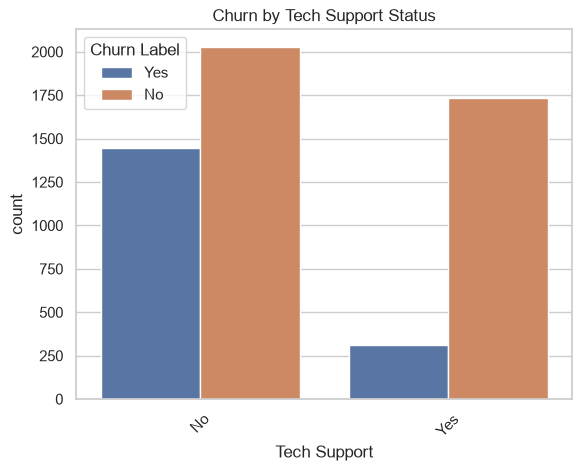

In [ ]:
sns.countplot(data=df[df['Tech Support'] != 'No internet service'], x='Tech Support', hue='Churn Label')
plt.title('Churn by Tech Support Status')
plt.xticks(rotation=45)
plt.show()

Customers with no tech support have a higher churn rate.
- Has no tech support churn rate: 41.64%
- Has tech support churn rate: 15.17%

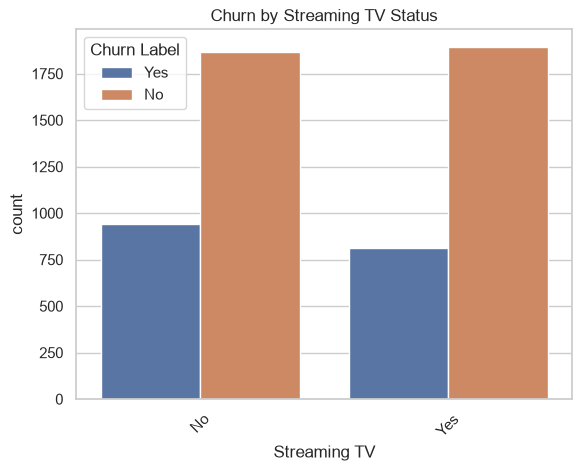

In [ ]:
sns.countplot(data=df[df['Streaming TV'] != 'No internet service'], x='Streaming TV', hue='Churn Label')
plt.title('Churn by Streaming TV Status')
plt.xticks(rotation=45)
plt.show()

Streaming TV services doesn't differentiate churn rate by much.
- Streams TV churn rate: 30.07%
- Doesn't stream tv churn rate: 33.52%

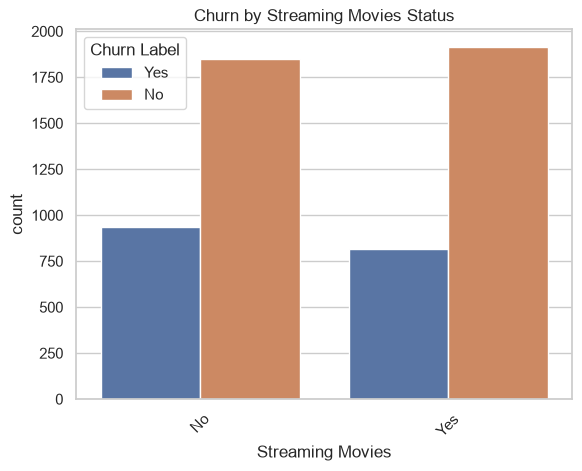

In [ ]:
sns.countplot(data=df[df['Streaming Movies'] != 'No internet service'], x='Streaming Movies', hue='Churn Label')
plt.title('Churn by Streaming Movies Status')
plt.xticks(rotation=45)
plt.show()

Streaming movies services doesn't differentiate churn rate by much.
- Streams movies churn rate: 29.94%
- Doesn't stream movies churn rate: 33.68%

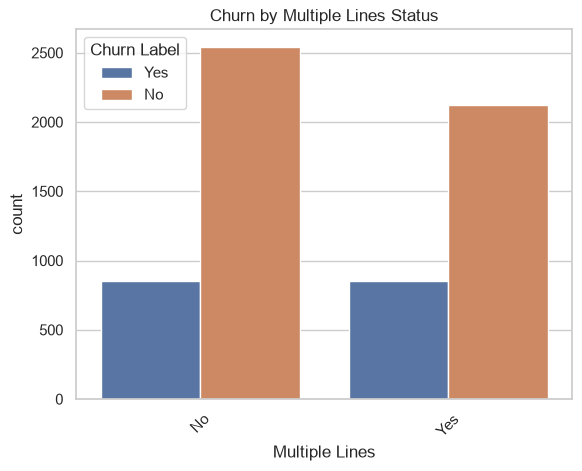

In [ ]:
sns.countplot(data=df[df['Multiple Lines'] != 'No phone service'], x='Multiple Lines', hue='Churn Label')
plt.title('Churn by Multiple Lines Status')
plt.xticks(rotation=45)
plt.show()

Having multiple lines doesn't differentiate churn rate by much.
- Has multiple lines churn rate: 28.61%
- Doesn't have multiple lines churn rate: 25.04%

Across all services offerings, it appears that a lack of services, especially tech support, device protection, and online backup, result in a much higher churn rate.

## Categorical Features and Their Churn Rates Listed

In [ ]:
for col in categorical_cols:
    print(f'\n--- {col} ---')
    print(
        pd.crosstab(
            df[col],
            df['Churn Label'],
            normalize='index'
        ) * 100
    )


--- Gender ---
Churn Label     No    Yes
Gender                   
Female      73.079 26.921
Male        73.840 26.160

--- Senior Citizen ---
Churn Label        No    Yes
Senior Citizen              
No             76.394 23.606
Yes            58.319 41.681

--- Partner ---
Churn Label     No    Yes
Partner                  
No          67.042 32.958
Yes         80.335 19.665

--- Dependents ---
Churn Label     No    Yes
Dependents               
No          67.448 32.552
Yes         93.485  6.515

--- Phone Service ---
Churn Label       No    Yes
Phone Service              
No            75.073 24.927
Yes           73.290 26.710

--- Multiple Lines ---
Churn Label          No    Yes
Multiple Lines                
No               74.956 25.044
No phone service 75.073 24.927
Yes              71.390 28.610

--- Internet Service ---
Churn Label          No    Yes
Internet Service              
DSL              81.041 18.959
Fiber optic      58.107 41.893
No               92.595  7.405


## Numeric Features Correlation

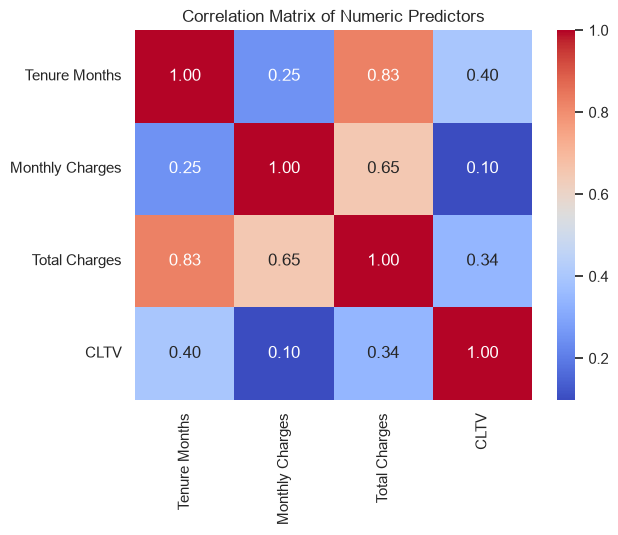

In [ ]:
numeric_predictors = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV'
]

sns.heatmap(
    df[numeric_predictors].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Matrix of Numeric Predictors')
plt.show()

Correlations between numeric features is only seen mostly between charges and tenure months.

Notable features for identifying churn rate:
- Tenure months
- Monthly charges
- Total charges
- Contract Type
- Internet Service type
- Payment Method
- Senior Citizen
- Dependents
- Online Security
- Online Backup
- Device Protection
- Tech Support

# Training and Testing Data

Explanation for columns being dropped:
- Lat Long: Combines data from longitude and latitude
- Longitude: Customers are concetrated in California, latitude and longitude aren't important to churn after eda investigation
- Latitude: Same as Longitude
- CustomerID: Just a method to identify customers, not neded to predict churn
- Country: All customers are domestic
- Churn Label: This is the class, not needed for prediction
- Count: Count of customers not needed
- Churn Score: This score was made using an IBM prediction system, results in data leakage, removed
- Churn Reason: Data leakage, as only customers who have churned have a churn reason
- CLTV: Customer lifetime value. This feature is good for deciding what customers to prioritize, but not needed to predict churn
- City: Lots of cities have below 20 customers, these low numbers make cities an unreliable metric for predicting churn.
- Zip code: Same case but more extreme as city

In [ ]:
drop_cols = ['CustomerID', 'Country', 'Lat Long', 'Churn Label', 'Churn Value', 'Count',
             'Churn Score', 'Churn Reason', 'CLTV', 'State', 'City', 'Zip Code', 'Latitude', 'Longitude']

X = df.drop(columns=drop_cols)
y = df['Churn Value']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    stratify=y
)

# Predictive Modeling and Interpretation

This section extends the existing analysis into predictive modeling. The goal is to predict whether a customer will churn and compare three classification approaches using the customer information retained after the exploratory analysis. The emphasis is on the predictive accuracy of the models for previously unseen customers rather than on fitting the existing data as well as possible. Logistic regression, k-nearest neighbors and random forest models are three different approaches to the binary classification to compare.


In [ ]:
numeric_features = X_train.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("numeric",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),numeric_features),
    ("categorical",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical_features)
])

print("Numeric predictors:",numeric_features)
print("Categorical predictors:",categorical_features)


Numeric predictors: ['Tenure Months', 'Monthly Charges', 'Total Charges']
Categorical predictors: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


C:\Users\mlmug\AppData\Local\Temp\ipykernel_22000\1123419397.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.


## Baseline Model



In [ ]:
baseline_model = DummyClassifier(strategy="most_frequent",random_state=1)

baseline_model.fit(X_train, y_train)
baseline_prediction = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test,baseline_prediction)

print(f"Baseline validation accuracy: {baseline_accuracy:.3f}")


Baseline validation accuracy: 0.735


## Logistic Regression

Logistic regression is a simple classification model and provides a baseline for comparing the other models. Because churn is imbalanced, class weights are used to give more importance to the churn class. The regularization parameter C is tuned using five-fold cross-validation with ROC AUC as the scoring metric.


In [ ]:
logistic_pipeline = Pipeline([("preprocessor",preprocessor),("model",LogisticRegression(max_iter=1000,class_weight="balanced",random_state=1))])

logistic_grid = GridSearchCV(logistic_pipeline,param_grid={"model__C":[0.1,1,10]},scoring="roc_auc",cv=5,n_jobs=-1)
logistic_grid.fit(X_train,y_train)

logistic_validation_probability = logistic_grid.predict_proba(X_test)[:,1]
logistic_validation_prediction = (logistic_validation_probability >= 0.50).astype(int)

print("Best logistic regression parameters:")
print(logistic_grid.best_params_)


Best logistic regression parameters:
{'model__C': 1}


### Validation Results


In [ ]:
logistic_results = pd.DataFrame({"Metric":["Accuracy","Precision","Recall","F1","ROC AUC"],
                                 "Validation":[accuracy_score(y_test,logistic_validation_prediction),
                                               precision_score(y_test,logistic_validation_prediction),
                                               recall_score(y_test,logistic_validation_prediction),
                                               f1_score(y_test,logistic_validation_prediction),
                                               roc_auc_score(y_test,logistic_validation_probability)]})

display(logistic_results)

,Metric,Validation
0,Accuracy,0.760
1,Precision,0.531
2,Recall,0.807
3,F1,0.641
4,ROC AUC,0.853


The logistic regression model had a validation ROC AUC of around 0.853. This means that the model was generally able to distinguish between customers that churned and those that did not. Its recall was around 80.7%, which means the model was able to find most of the actual churn cases in the validation data. But the accuracy of it was about 76.0%, so there were still a fair number of incorrect classifications. The results suggest the logistic regression was particularly useful to identify potential churners but have to compare the performance with other models to select the final model.


## k-Nearest Neighbors

k-NN classifies a customer using the outcomes of nearby observations in predictor space. The number of neighbors and weighting method are tuned using five-fold cross-validation. A small set of candidate values is used to keep the analysis straightforward while still testing whether the neighborhood size affects predictive performance.


In [ ]:
knn_pipeline = Pipeline([("preprocessor",preprocessor),("model",KNeighborsClassifier())])

knn_grid = GridSearchCV(knn_pipeline,param_grid={"model__n_neighbors":[5,15,25],"model__weights":["uniform","distance"]},scoring="roc_auc",cv=5,n_jobs=-1)
knn_grid.fit(X_train,y_train)

knn_validation_probability = knn_grid.predict_proba(X_test)[:,1]
knn_validation_prediction = (knn_validation_probability >= 0.50).astype(int)

print("Best k-NN parameters:")
print(knn_grid.best_params_)

Best k-NN parameters:
{'model__n_neighbors': 25, 'model__weights': 'uniform'}


### Validation Results


In [ ]:
knn_results = pd.DataFrame({"Metric":["Accuracy","Precision","Recall","F1","ROC AUC"],
                            "Validation":[accuracy_score(y_test,knn_validation_prediction),
                                          precision_score(y_test,knn_validation_prediction),
                                          recall_score(y_test,knn_validation_prediction),
                                          f1_score(y_test,knn_validation_prediction),
                                          roc_auc_score(y_test,knn_validation_probability)]})

display(knn_results)


,Metric,Validation
0,Accuracy,0.798
1,Precision,0.627
2,Recall,0.587
3,F1,0.606
4,ROC AUC,0.838


### Interpretation

k-NN provides a different approach by classifying customers based on similarity to other customers. In this dataset, the model achieved a validation ROC AUC of about 0.838 and recall of about 58.6%, meaning it identified fewer actual churners than logistic regression. The model also requires both numeric variables to be standardized and categorical variables to be one-hot encoded, which is especially important here because the dataset contains many categorical customer and service variables.


## Random Forest

Random forest is included as exploratory analysis because churn may depend on combinations of contract type, tenure, charges and service characteristics. These relationships may not be well described by a single linear boundary. The model is tuned on a small grid of tree depth and minimum leaf size with number of trees fixed at 200.


In [ ]:
random_forest_pipeline = Pipeline([("preprocessor",preprocessor),("model",RandomForestClassifier(n_estimators=200,class_weight="balanced",random_state=1,n_jobs=-1))])

random_forest_grid = GridSearchCV(random_forest_pipeline,param_grid={"model__max_depth":[5,10,None],"model__min_samples_leaf":[1,5]},scoring="roc_auc",cv=5,n_jobs=-1)
random_forest_grid.fit(X_train,y_train)

rf_validation_probability = random_forest_grid.predict_proba(X_test)[:,1]
rf_validation_prediction = (rf_validation_probability >= 0.50).astype(int)

print("Best random forest parameters:")
print(random_forest_grid.best_params_)

Best random forest parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 5}


### Validation Results


In [ ]:
rf_results = pd.DataFrame({"Metric":["Accuracy","Precision","Recall","F1","ROC AUC"],
                           "Validation":[accuracy_score(y_test,rf_validation_prediction),
                                         precision_score(y_test,rf_validation_prediction),
                                         recall_score(y_test,rf_validation_prediction),
                                         f1_score(y_test,rf_validation_prediction),
                                         roc_auc_score(y_test,rf_validation_probability)]})

display(rf_results)


,Metric,Validation
0,Accuracy,0.761
1,Precision,0.534
2,Recall,0.799
3,F1,0.640
4,ROC AUC,0.856


The random forest performed well on the validation data, with a ROC AUC of about 0.855, recall of about 77.5%, and F1 score of about 64.5%. This means it was able to identify a large portion of the customers who actually churned while maintaining a similar overall performance to logistic regression.


## Compare Models

The models are compared using the same validation data. ROC AUC is the primary comparison measure. F1, recall, precision, and accuracy are also reported to show the trade-offs at the 0.50 classification cutoff.


In [ ]:
model_comparison = pd.DataFrame({
    "Model":["Logistic Regression","k-NN","Random Forest"],
    "Accuracy":[accuracy_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "Precision":[precision_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "Recall":[recall_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "F1":[f1_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "ROC AUC":[roc_auc_score(y_test,p) for p in [logistic_validation_probability,knn_validation_probability,rf_validation_probability]]
})

display(model_comparison.sort_values("ROC AUC",ascending=False).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Random Forest,0.761,0.534,0.799,0.640,0.856
1,Logistic Regression,0.760,0.531,0.807,0.641,0.853
2,k-NN,0.798,0.627,0.587,0.606,0.838


# Final Model Selection

Logistic regression had the highest recall at about 80.7%, while k-NN had the lowest recall at about 58.6% and a ROC AUC of about 0.838. Random forest had the highest ROC AUC at about 0.855, with a recall of about 77.5% and an F1 score of about 64.5%. Based on these results, random forest was selected because it provided the strongest overall ability to distinguish between customers who churned and those who did not. This decision is based on the validation performance of the models, and the variables identified by the model should be viewed as useful predictors.


In [ ]:
selected_model_name = "Random Forest"
selected_model = random_forest_grid.best_estimator_

print(f"Selected model: {selected_model_name}")
print(f"Best parameters: {random_forest_grid.best_params_}")


Selected model: Random Forest
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 5}


# Model Brief

**To:** Technical Project Team  
**Subject:** Customer Churn Predictive Modeling

### Modeling Approach

The goal was to identify customers at risk of churn to help prioritize retention efforts. Based on exploratory analysis, we retained relevant customer attributes such as contract type, tenure, charges, and service usage while excluding identifiers and target related fields that could introduce data leakage.

We compared logistic regression, k-nearest neighbors, and random forest. Logistic regression achieved the highest validation recall with 80.7%, while k-NN had the highest accuracy and precision. Random forest achieved the strongest validation ROC AUC 0.856, providing the best overall ability to distinguish between customers who churn and those who stay.

### Evaluation and Limitations

We used five-fold cross-validation to tune model settings and selected random forest based on validation performance. ROC AUC was the primary metric because it measures how well a model distinguishes churners from non-churners without relying on a single classification threshold, which is useful when the target classes are imbalanced.

The results show that random forest identifies a substantial proportion of actual churners, but its precision of 53.4% indicates that many flagged customers may not churn. Feature importance highlighted customer characteristics associated with churn, but these relationships do not establish causation. The model also produces false positives and false negatives, so predictions should guide prioritization rather than be treated as certain outcomes.

### Recommended Next Steps

Conduct a controlled retention pilot comparing targeted outreach with a similar comparison group. Measure churn rates, intervention costs, and retained revenue to determine whether the strategy delivers measurable business value.

# Business Applications

The purpose of this portion of the project is to take the interpretation a step further to hopefully identify customer types that are more or less likely to churn.

In [ ]:
# creating a data frame (df2) with the predicted churn probabilities and predicted churn result

df2 = df.copy()

drop_cols2 = ['CustomerID', 'Country', 'Lat Long', 'Churn Label', 'Count', 'State', 'City', 'Zip Code', 'Latitude', 'Longitude']

df2 = df.drop(columns=drop_cols2)

X2 = df2.drop(columns = ["Churn Value", "Churn Score", "CLTV", "Churn Reason"])

rf_prob = random_forest_grid.predict_proba(X2)[:,1]
rf_pred = (rf_prob >= 0.50).astype(int)

df2["rf_prob"] = rf_prob
df2["rf_pred"] = rf_pred

pd.set_option('display.max_columns', None)
df2.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason,rf_prob,rf_pred
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150,1,86,3239,Competitor made better offer,0.635,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.650,1,67,2701,Moved,0.824,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.650,820.500,1,86,5372,Moved,0.701,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.800,3046.050,1,84,5003,Moved,0.421,0
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.700,5036.300,1,89,5340,Competitor had better devices,0.480,0


In [ ]:
# overall churn statistics (without clustering)

total_customers = len(df2)

actual_churn_count = df2['Churn Value'].sum()
predicted_churn_count = df2['rf_pred'].sum()

unclustered_summary = pd.DataFrame({
    'Metric': [
        'Total Customers',
        'Actual Churn Count',
        'Actual Churn Rate (%)',
        'Predicted Churn Count',
        'Predicted Churn Rate (%)'
    ],
    'Value': [
        total_customers,
        actual_churn_count,
        df2['Churn Value'].mean() * 100,
        predicted_churn_count,
        df2['rf_pred'].mean() * 100
    ]
})

display(unclustered_summary.round(2))

,Metric,Value
0,Total Customers,7043.000
1,Actual Churn Count,1869.000
2,Actual Churn Rate (%),26.540
3,Predicted Churn Count,2791.000
4,Predicted Churn Rate (%),39.630


In [ ]:
# comparing proportions of actual and predicted churners against the entire dataset

cat_cols = ["Gender", "Senior Citizen", "Partner", "Dependents", "Phone Service", "Multiple Lines", "Internet Service",
"Online Security", "Online Backup", "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies", "Contract",
"Paperless Billing", "Payment Method"]

num_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]

actual_churn = "Churn Value"
pred_churn = "rf_pred"

total_n = len(df2)

categorical_rows2 = []

for col in cat_cols:
    if col not in df2.columns:
        continue

    for category, group in df2.groupby(
        col, dropna=False, observed=True
    ):
        n = len(group)

        actual_count = (group[actual_churn] == 1).sum()
        predicted_count = (group[pred_churn] == 1).sum()

        categorical_rows2.append({
            "Variable": col,
            "Category": str(category),

            # Category prevalence in the entire dataset
            "Category Count": n,
            "Category % of Dataset": round(
                n / total_n * 100, 1
            ) if total_n else 0,

            # Actual churn prevalence
            "Actual Churn Count": actual_count,
            "Actual Churn Rate of Group (%)": round(
                actual_count / n * 100, 1
            ) if n else 0,
            "Actual Churn Rate of Dataset (%)": round(
                actual_count / total_n * 100, 1
            ) if total_n else 0,

            # Predicted churn prevalence
            "Predicted Churn Count": predicted_count,
            "Predicted Churn Rate of Group (%)": round(
                predicted_count / n * 100, 1
            ) if n else 0,
            "Predicted Churn Rate of Dataset (%)": round(
                predicted_count / total_n * 100, 1
            ) if total_n else 0
        })

categorical_table2 = pd.DataFrame(categorical_rows2)

categorical_table2 = categorical_table2.sort_values(
    by="Actual Churn Rate of Group (%)",
    ascending=False
).reset_index(drop=True)

display(
    categorical_table2.style.format({
        "Category % of Dataset": "{:.1f}",
        "Actual Churn Rate of Group (%)": "{:.1f}",
        "Actual Churn Rate of Dataset (%)": "{:.1f}",
        "Predicted Churn Rate of Group (%)": "{:.1f}",
        "Predicted Churn Rate of Dataset (%)": "{:.1f}"
    })
)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

,Variable,Category,Category Count,Category % of Dataset,Actual Churn Count,Actual Churn Rate of Group (%),Actual Churn Rate of Dataset (%),Predicted Churn Count,Predicted Churn Rate of Group (%),Predicted Churn Rate of Dataset (%)
0,Payment Method,Electronic check,2365,33.6,1071,45.3,15.2,1638,69.3,23.3
1,Contract,Month-to-month,3875,55.0,1655,42.7,23.5,2624,67.7,37.3
2,Internet Service,Fiber optic,3096,44.0,1297,41.9,18.4,2024,65.4,28.7
3,Online Security,No,3498,49.7,1461,41.8,20.7,2277,65.1,32.3
4,Senior Citizen,Yes,1142,16.2,476,41.7,6.8,728,63.7,10.3
5,Tech Support,No,3473,49.3,1446,41.6,20.5,2246,64.7,31.9
6,Online Backup,No,3088,43.8,1233,39.9,17.5,1941,62.9,27.6
7,Device Protection,No,3095,43.9,1211,39.1,17.2,1899,61.4,27.0
8,Streaming Movies,No,2785,39.5,938,33.7,13.3,1485,53.3,21.1
9,Paperless Billing,Yes,4171,59.2,1400,33.6,19.9,2065,49.5,29.3


When breaking the categorical columns into their categories, or groups, the proportion of churners can help to start build a profile of customers based on churn. For example, of those who have a month-to-month contract, 42.7% of them have churned, where as those who have a two-month contract, 2.8% of them have churned. Ultimately, this table identifies categories or groups with high (and low) churn rates, and could be used to build an image of high and low risk churn customers.

In addition, this table allows for a direct comparison of the actual churn counts and percentages (within a category and against the entire dataset) with that of the random forests-generated predictions. The model appears to overpredict churn, proportionally to the magnitude of the value. For example, 1071 customers paying via electronic check churned (45.3% of group), but the model predicted 1638 customers (69.3% of group). In comparison, 232 customers paying via automatic credit card payments churned (15.2%), but the model predicted 328 (21.6%).

Lastly, this table shows, when looking at all churners against the entire dataset, how much each category or group contributes to churn. For example, of all customers who churned, 18.4% used fiber optics for their internet service and 6.5% of them used DSL.

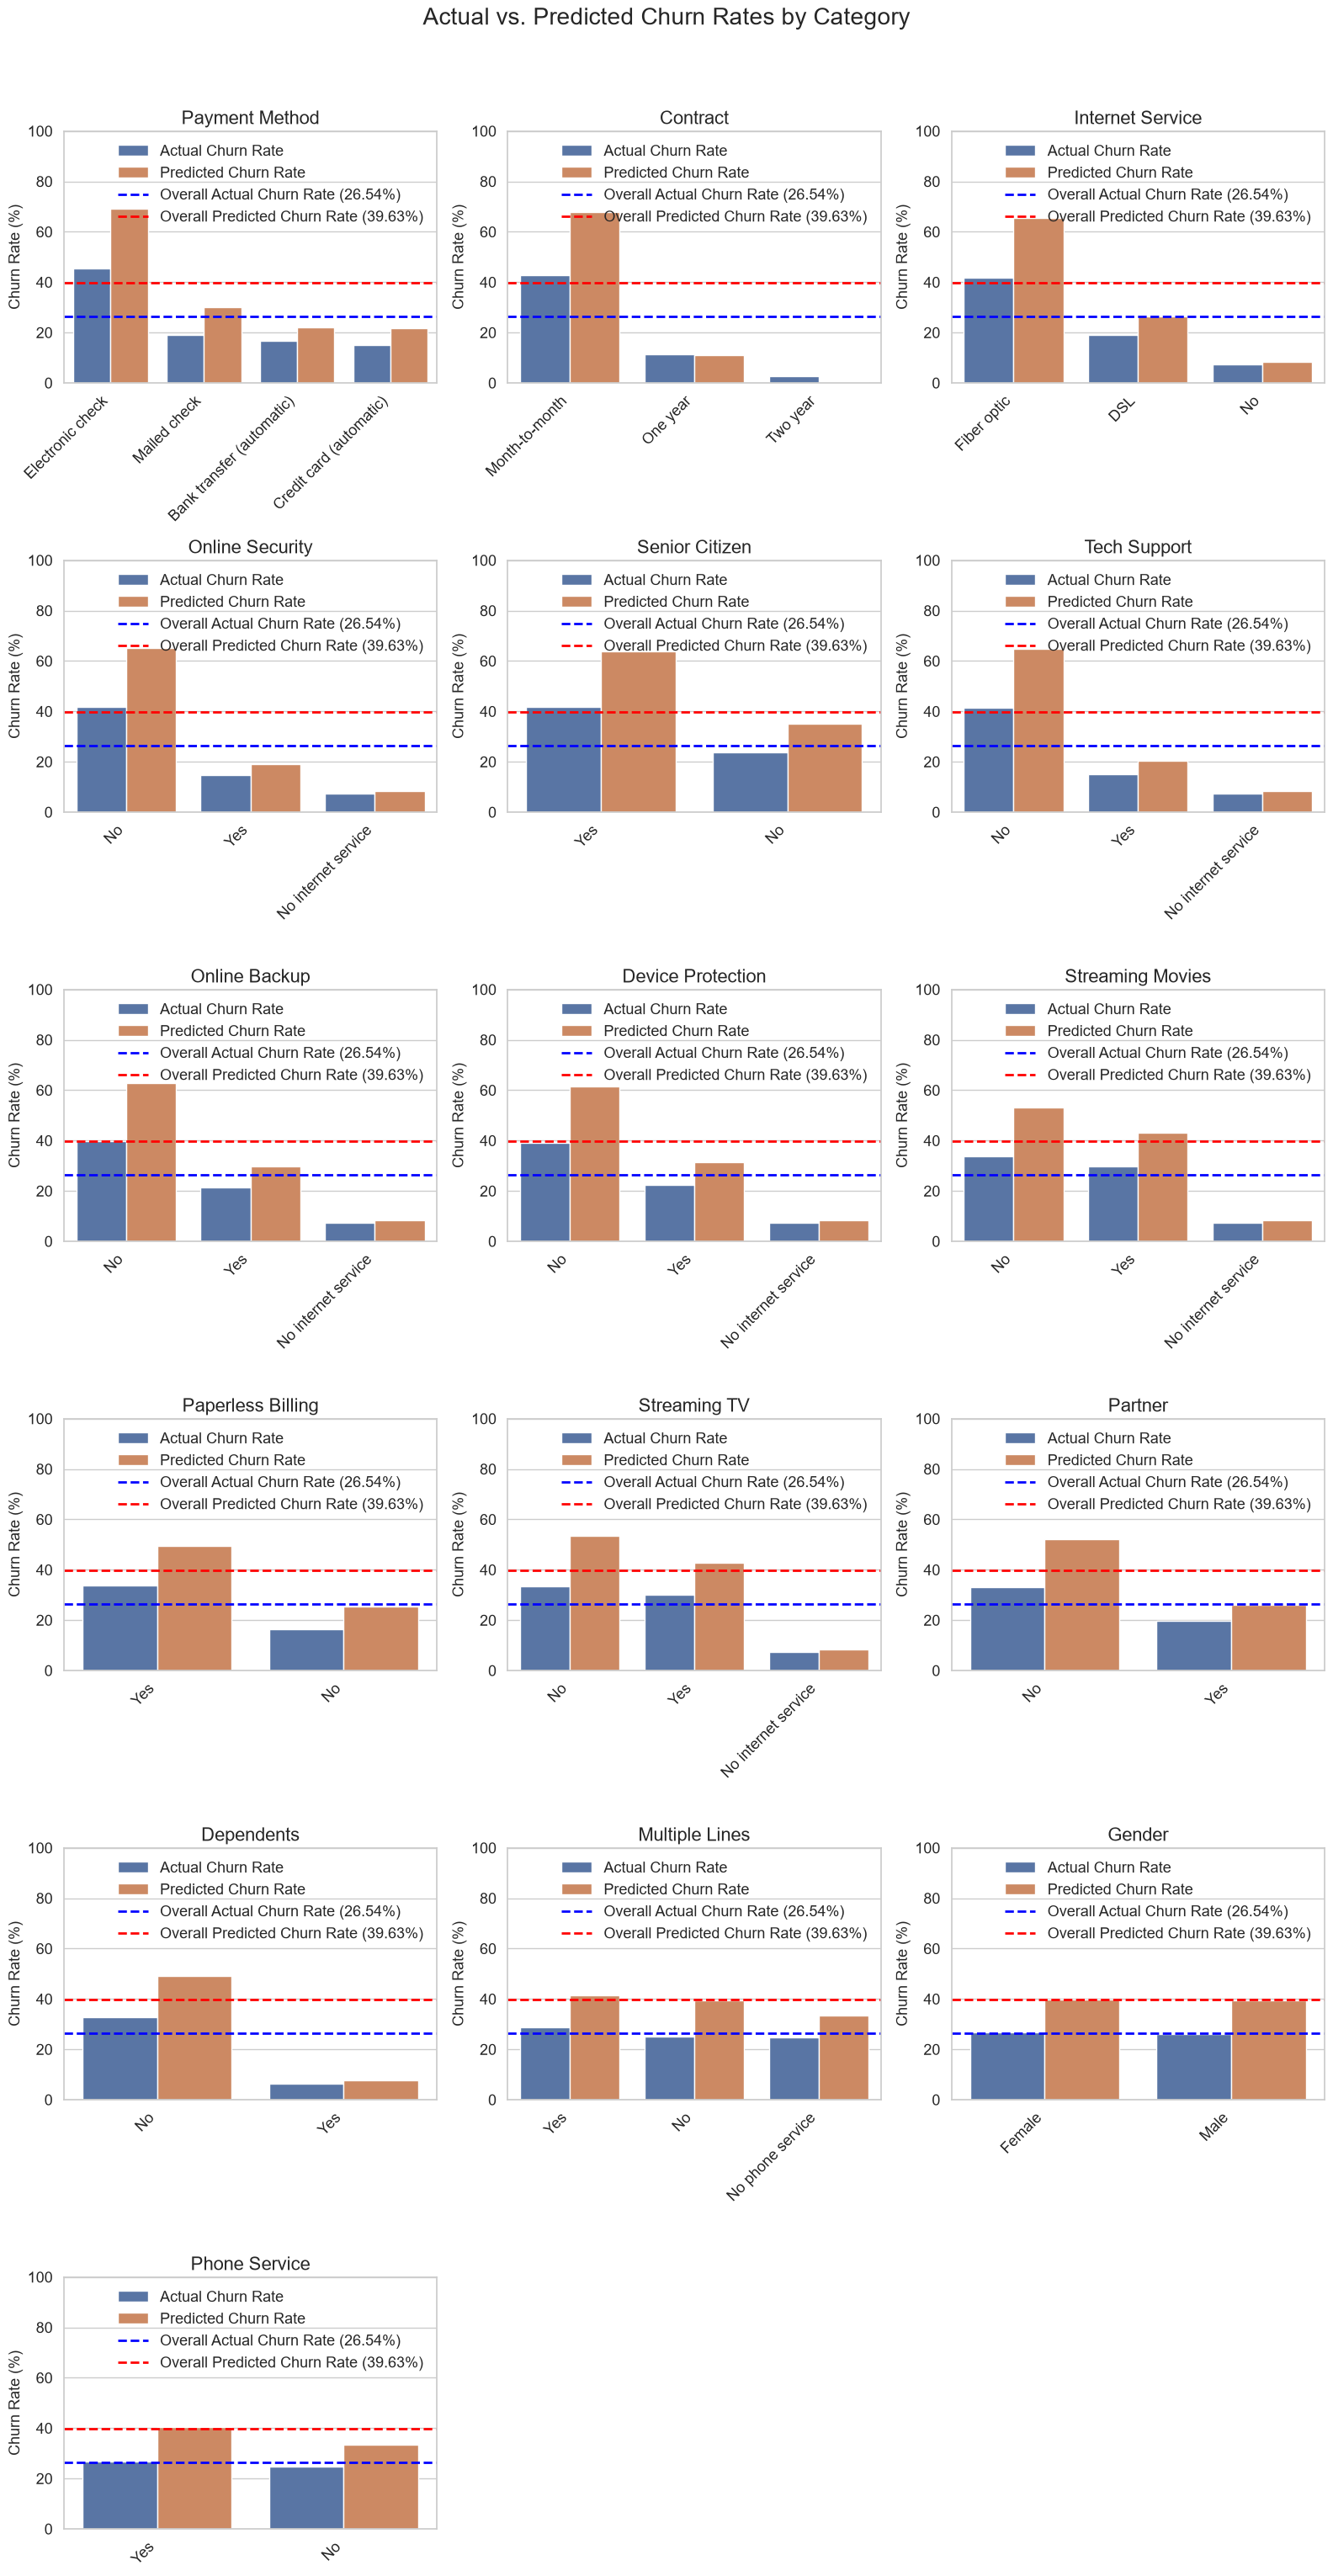

In [ ]:
# visualize differences in actual and predicted in-group churn rates for each category

sns.set_theme(style = "whitegrid")

# Column names
variable_col = "Variable"
category_col = "Category"
actual_col = "Actual Churn Rate of Group (%)"
predicted_col = "Predicted Churn Rate of Group (%)"

# Identify variables to plot
variables = categorical_table2[variable_col].unique()

# Matrix layout
n_cols = 3
n_rows = (len(variables) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize = (16, 5 * n_rows),
    squeeze = False
)

axes = axes.flatten()

for i, variable in enumerate(variables):
    ax = axes[i]

    plot_data = categorical_table2[
        categorical_table2[variable_col] == variable
    ].copy()

    # Sort categories by actual churn rate
    plot_data = plot_data.sort_values(
        by = actual_col,
        ascending = False
    )

    # Reshape data for grouped bars
    plot_data = plot_data.melt(
        id_vars = [category_col],
        value_vars = [actual_col, predicted_col],
        var_name = "Churn Type",
        value_name = "Churn Rate (%)"
    )

    plot_data["Churn Type"] = plot_data["Churn Type"].map({
        actual_col: "Actual Churn Rate",
        predicted_col: "Predicted Churn Rate"
    })

    sns.barplot(
        data=plot_data,
        x = category_col,
        y = "Churn Rate (%)",
        hue = "Churn Type",
        hue_order = ["Actual Churn Rate", "Predicted Churn Rate"],
        #palette = palette,
        ax = ax
    )

    # Add horizontal reference line for overall churn
    ax.axhline(
        y=26.54,
        color="blue",
        linestyle="--",
        linewidth=2,
        label="Overall Actual Churn Rate (26.54%)"
    )

    ax.axhline(
            y=39.63,
            color="red",
            linestyle="--",
            linewidth=2,
            label="Overall Predicted Churn Rate (39.63%)"
        )

    ax.set_title(f"{variable}", fontsize = 16)
    ax.set_xlabel("", fontsize = 13)
    ax.set_ylabel("Churn Rate (%)", fontsize = 13)
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", labelsize = 13, rotation = 45)
    ax.tick_params(axis="y", labelsize = 13)
    ax.legend(title="", fontsize=13, framealpha = 0)

    # Align category labels
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

# Remove unused subplots
for j in range(len(variables), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Actual vs. Predicted Churn Rates by Category",
    fontsize=20,
    y=1.02
)

plt.tight_layout()
plt.show()

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

This series of graphs provides a comprehensive summary of how the actual and predicted churn rates within each group in a category compared to the overall actual and predicted churn rates. The predicted churn rates were consistent with the actual churn rates in that when the actual churn rate of each group exceeded the overall actual churn rate, the predicted churn rate of each group also exceeded the overall predicted churn rate. Taken together, this data is starting to generate an image of what a higher-risk churner might look like. I could expect that the high-churn customer type would be senior citizens who use a month-to-month contract, pay via electronic check, use fiber optic internet service, and do not use HorizonTel's online backup or device protection services.

In [ ]:
# describe the numerical columns

df2[["Tenure Months", "Monthly Charges", "Total Charges"]].describe()

,Tenure Months,Monthly Charges,Total Charges
count,7043.000,7043.000,7043.000
mean,32.371,64.762,2279.734
std,24.559,30.090,2266.794
min,0.000,18.250,0.000
25%,9.000,35.500,398.550
50%,29.000,70.350,1394.550
75%,55.000,89.850,3786.600
max,72.000,118.750,8684.800


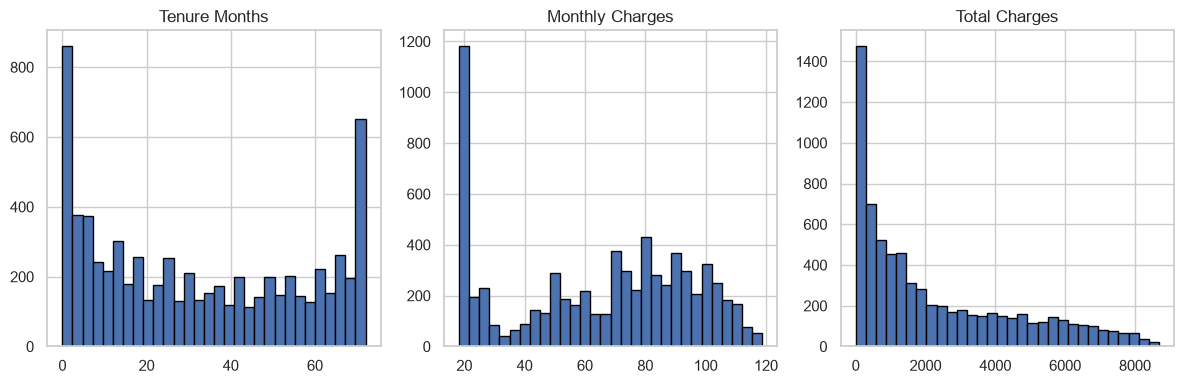

In [ ]:
# visualizing distribution of numerical columns

df2[["Tenure Months", "Monthly Charges", "Total Charges"]].hist(
    figsize=(12, 4),
    bins=30,
    layout=(1, 3),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [ ]:
# comparing proportions of actual and predicted churners against the entire dataset

group_rows_num = []

for col in num_cols:
    # Convert to numeric and exclude missing values for bin creation
    values = pd.to_numeric(df2[col], errors="coerce")

    # Create up to 4 quantile-based groups
    try:
        bins = pd.qcut(
            values,
            q=4,
            duplicates="drop"
        )
    except ValueError:
        print(f"Skipping {col}: unable to create groups.")
        continue

    temp = df2.copy()
    temp["_range"] = bins

    for category, group in temp.groupby(
        "_range", observed=True
    ):
        n = len(group)
        total_n = len(df2)

        actual_count = (group[actual_churn] == 1).sum()
        predicted_count = (group[pred_churn] == 1).sum()

        group_rows_num.append({
            "Variable": col,
            "Range": str(category),
            "Group Size": n,
            "Category % of Dataset": round(
                n / total_n * 100, 1
            ) if total_n else 0,
            "Actual Churn Count": actual_count,
            "Actual Churn Rate of Group (%)": round(
                actual_count / n * 100, 1
            ) if n else 0,
            "Actual Churn Rate of Dataset (%)": round(
                actual_count / total_n * 100, 1
            ) if n else 0,
            "Predicted Churn Count": predicted_count,
            "Predicted Churn Rate of Group (%)": round(
                predicted_count / n * 100, 1
            ) if n else 0,
            "Predicted Churn Rate of Dataset (%)": round(
                predicted_count / total_n * 100, 1
            ) if n else 0
        })

numerical_group_table = pd.DataFrame(group_rows_num)

numerical_group_table = numerical_group_table.sort_values(
    ["Actual Churn Count"],
    ascending=[False]
).reset_index(drop=True)

#display(numerical_group_table)

display(
    numerical_group_table.style.format({
        "Category % of Dataset": "{:.1f}",
        "Actual Churn Rate of Group (%)": "{:.1f}",
        "Actual Churn Rate of Dataset (%)": "{:.1f}",
        "Predicted Churn Rate of Group (%)": "{:.1f}",
        "Predicted Churn Rate of Dataset (%)": "{:.1f}"
    })
)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

,Variable,Range,Group Size,Category % of Dataset,Actual Churn Count,Actual Churn Rate of Group (%),Actual Churn Rate of Dataset (%),Predicted Churn Count,Predicted Churn Rate of Group (%),Predicted Churn Rate of Dataset (%)
0,Tenure Months,"(-0.001, 9.0]",1854,26.3,923,49.8,13.1,1404,75.7,19.9
1,Total Charges,"(-0.001, 398.55]",1762,25.0,762,43.2,10.8,1139,64.6,16.2
2,Monthly Charges,"(70.35, 89.85]",1757,24.9,659,37.5,9.4,1008,57.4,14.3
3,Monthly Charges,"(89.85, 118.75]",1758,25.0,578,32.9,8.2,874,49.7,12.4
4,Tenure Months,"(9.0, 29.0]",1715,24.4,486,28.3,6.9,748,43.6,10.6
5,Total Charges,"(398.55, 1394.55]",1760,25.0,447,25.4,6.3,652,37.0,9.3
6,Monthly Charges,"(35.5, 70.35]",1766,25.1,434,24.6,6.2,650,36.8,9.2
7,Total Charges,"(1394.55, 3786.6]",1760,25.0,405,23.0,5.8,620,35.2,8.8
8,Tenure Months,"(29.0, 55.0]",1719,24.4,324,18.8,4.6,476,27.7,6.8
9,Total Charges,"(3786.6, 8684.8]",1761,25.0,255,14.5,3.6,380,21.6,5.4


When dividing the numerical columns into bins, the proportion of churners can help to start build a profile of customers based on churn. For example, of customers with tenures of 9 months or less, 49.8% of them have churned, where as those 7.7% of customers with tenures of 55-72 months have churned. Ultimately, this table identifies categories or groups with high (and low) churn rates, and could be used to build an image of high and low risk churn customers.

In addition, this table allows for a direct comparison of the actual churn counts and percentages (within a category and against the entire dataset) with that of the random forests-generated predictions. Again, the model appears to overpredict churn, proportionally to the magnitude of the value. For example, 923 customers with tenures less than 9 months churned (49.8%), but the model predicted 1404 customers (75.7%). In comparison, 136 customers with 55-72 months of tenure churned 7.7% of the time, but the model predictd 163 customers (9.3%).

Lastly, this table shows, when looking at all churners against the entire dataset, how much each category or group contributes to churn. For example of all customers who churned, 13.3% of them had tenures of less than 9 months.

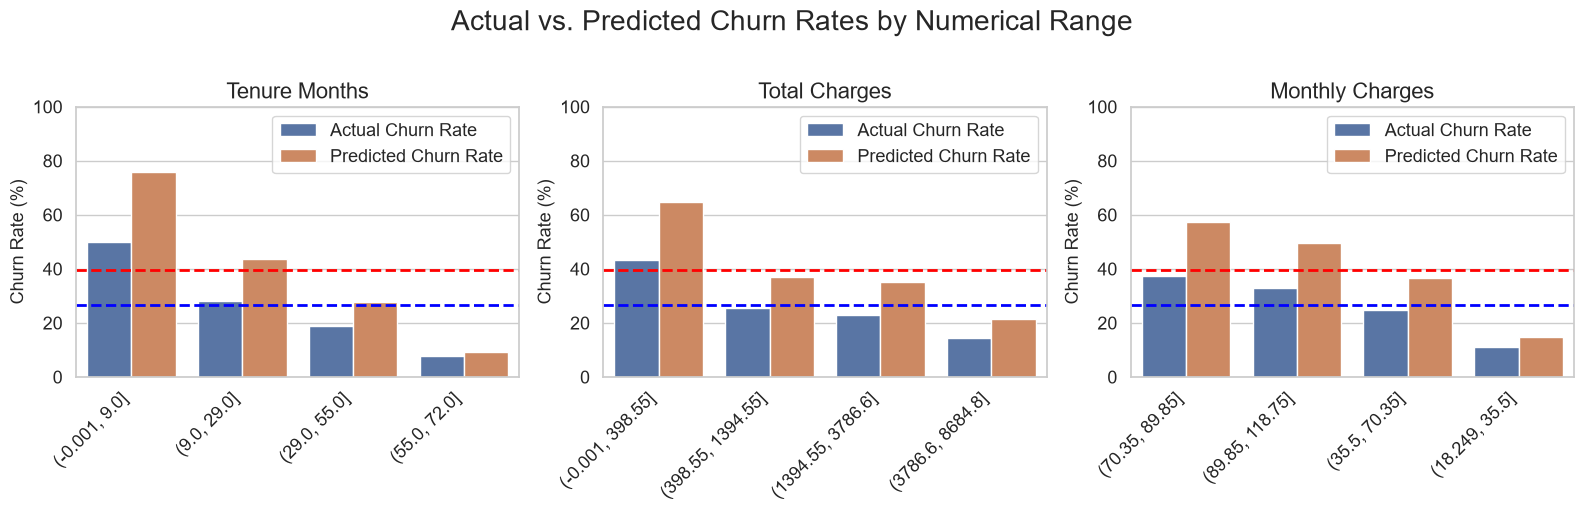

In [ ]:
# visualize differences in actual and predicted in-group churn rates for each category

sns.set_theme(style = "whitegrid")

# Column names
variable_col = "Variable"
numerical_col = "Range"
actual_col = "Actual Churn Rate of Group (%)"
predicted_col = "Predicted Churn Rate of Group (%)"

# Identify variables to plot
variables = numerical_group_table[variable_col].unique()

# Matrix layout
n_cols = 3
n_rows = (len(variables) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize = (16, 5 * n_rows),
    squeeze = False
)

axes = axes.flatten()

for i, variable in enumerate(variables):
    ax = axes[i]

    plot_data = numerical_group_table[
        numerical_group_table[variable_col] == variable
    ].copy()

    # Sort categories by actual churn rate
    plot_data = plot_data.sort_values(
        by = actual_col,
        ascending = False
    )

    # Reshape data for grouped bars
    plot_data = plot_data.melt(
        id_vars = [numerical_col],
        value_vars = [actual_col, predicted_col],
        var_name = "Churn Type",
        value_name = "Churn Rate (%)"
    )

    plot_data["Churn Type"] = plot_data["Churn Type"].map({
        actual_col: "Actual Churn Rate",
        predicted_col: "Predicted Churn Rate"
    })

    sns.barplot(
        data=plot_data,
        x = numerical_col,
        y = "Churn Rate (%)",
        hue = "Churn Type",
        hue_order = ["Actual Churn Rate", "Predicted Churn Rate"],
        #palette = palette,
        ax = ax
    )

    ax.set_title(f"{variable}", fontsize = 16)
    ax.set_xlabel("", fontsize = 13)
    ax.set_ylabel("Churn Rate (%)", fontsize = 13)
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", labelsize = 13, rotation = 45)
    ax.tick_params(axis="y", labelsize = 13)
    ax.legend(title="", fontsize=13)

# Add horizontal reference line for overall churn
    ax.axhline(
        y=26.54,
        color="blue",
        linestyle="--",
        linewidth=2,
        label="Overall Actual Churn Rate (26.54%)"
    )

    ax.axhline(
            y=39.63,
            color="red",
            linestyle="--",
            linewidth=2,
            label="Overall Predicted Churn Rate (39.63%)"
        )

    # Align category labels
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

# Remove unused subplots
for j in range(len(variables), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Actual vs. Predicted Churn Rates by Numerical Range",
    fontsize=20,
    y=1.02
)

plt.tight_layout()
plt.show()

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

This series of graphs provides a comprehensive summary of how the actual and predicted churn rates within each group in a category compared to the overall actual and predicted churn rates. The predicted churn rates were consistent with the actual churn rates in that when the actual churn rate of each group exceeded the overall actual churn rate, the predicted churn rate of each group also exceeded the overall predicted churn rate. Taken together, this data is starting to generate an image of what a higher-risk churner might look like. I could expect that the high-churn customer type might be someone with a tenure of less than nine months and total charges under $398.55.

## Identifying Customer Types via Clustering (K-prototype)

The K-prototype method was selected because of it was designed to handle a mixture of categorical and numerical data.

In [ ]:
df2.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason,rf_prob,rf_pred
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150,1,86,3239,Competitor made better offer,0.635,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.650,1,67,2701,Moved,0.824,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.650,820.500,1,86,5372,Moved,0.701,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.800,3046.050,1,84,5003,Moved,0.421,0
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.700,5036.300,1,89,5340,Competitor had better devices,0.480,0


In [ ]:
# prepare data frame for clustering

df2kx = df2.copy()

df2kx = df2kx.drop(columns = ["Churn Value", "Churn Score", "CLTV", "Churn Reason", "rf_prob", "rf_pred"])

df2kx.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.650
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.650,820.500
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.800,3046.050
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.700,5036.300


In [ ]:
# index the columns based on position

catColumnsPos = [df2kx.columns.get_loc(col) for col in list(df2kx.select_dtypes('object').columns)]
print('Categorical columns           : {}'.format(list(df2kx.select_dtypes('object').columns)))
print('Categorical columns position  : {}'.format(catColumnsPos))

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical).
# Towards Data Science.
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

Categorical columns           : ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']
Categorical columns position  : [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]


C:\Users\mlmug\AppData\Local\Temp\ipykernel_22000\3267335530.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
C:\Users\mlmug\AppData\Local\Temp\ipykernel_22000\3267335530.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes f

In [ ]:
# convert data frame to a matrix

df2Matrix = df2kx.to_numpy()

Cluster initiation: 1
Cluster initiation: 2
Cluster initiation: 3
Cluster initiation: 4
Cluster initiation: 5
Cluster initiation: 6
Cluster initiation: 7
Cluster initiation: 8
Cluster initiation: 9


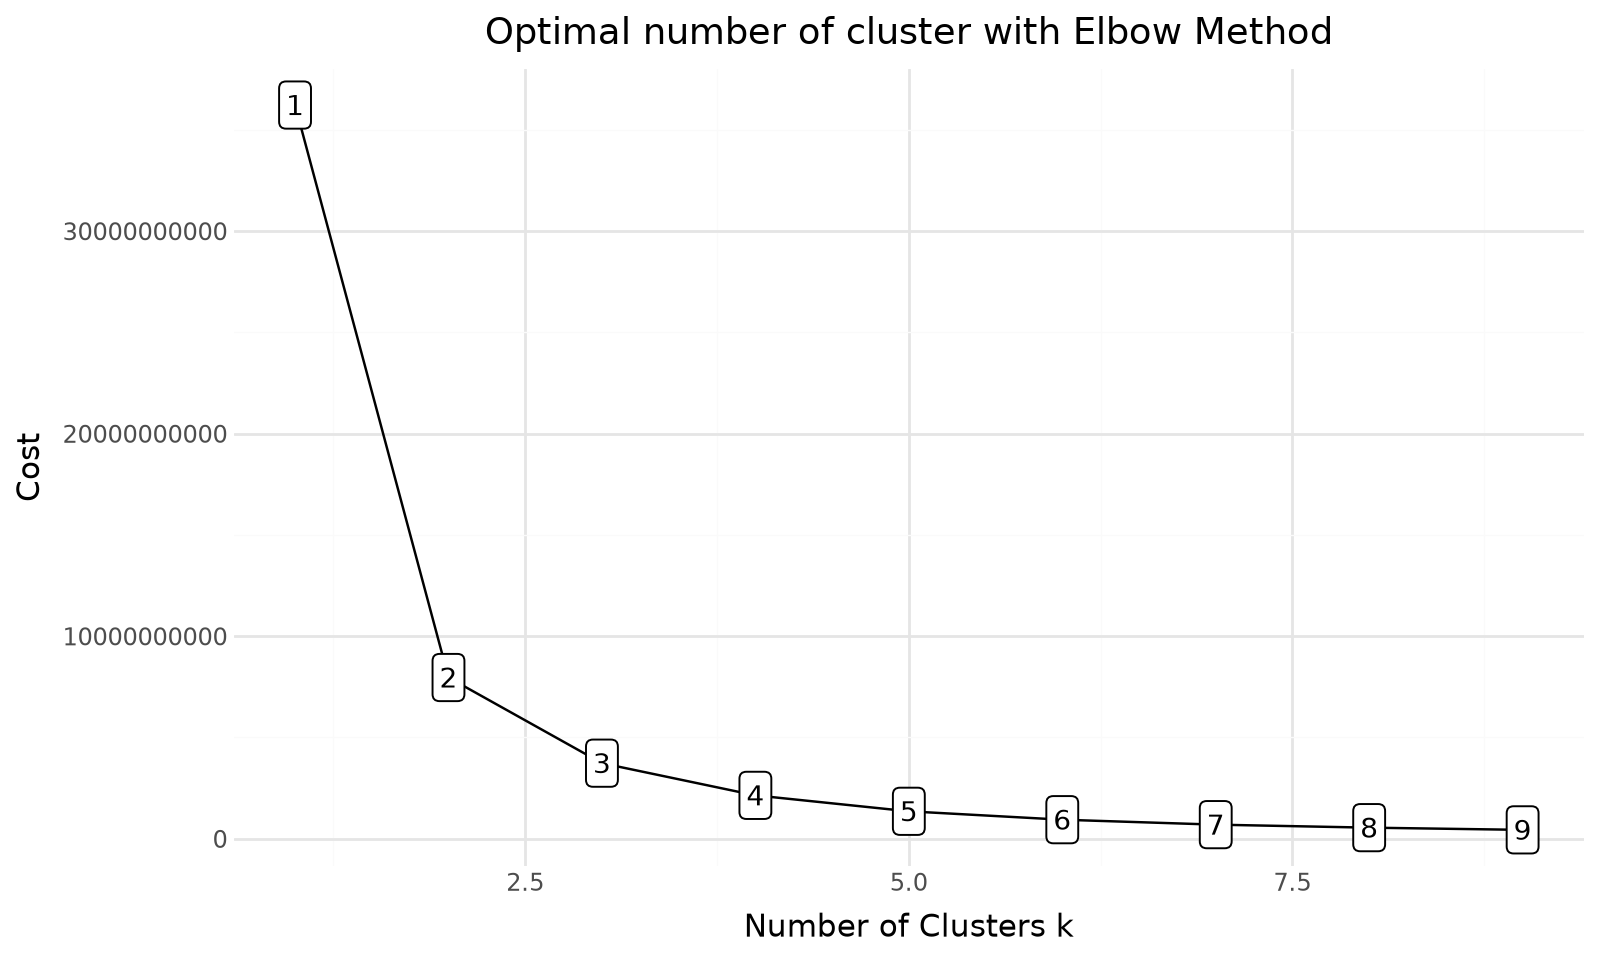

In [ ]:
# Choose optimal K using Elbow method

cost = []

for cluster in range(1, 10):
    try:
        kprototype = KPrototypes(n_jobs = -1, n_clusters = cluster, init = 'Huang', random_state = 0)
        kprototype.fit_predict(df2Matrix, categorical = catColumnsPos)
        cost.append(kprototype.cost_)
        print('Cluster initiation: {}'.format(cluster))
    except:
        break
# Converting the results into a dataframe and plotting them
df2_cost = pd.DataFrame({'Cluster':range(1, 10), 'Cost':cost})
# Data viz
plotnine.options.figure_size = (8, 4.8)
(
    ggplot(data = df2_cost)+
    geom_line(aes(x = 'Cluster',
                  y = 'Cost'))+
    geom_point(aes(x = 'Cluster',
                   y = 'Cost'))+
    geom_label(aes(x = 'Cluster',
                   y = 'Cost',
                   label = 'Cluster'),
               size = 10,
               nudge_y = 1000) +
    labs(title = 'Optimal number of cluster with Elbow Method')+
    xlab('Number of Clusters k')+
    ylab('Cost')+
    theme_minimal()
)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical).
# Towards Data Science.
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

Based on the elbow plot, a k = 2 clusters would be the ideal method for clustering.

The next step is evaluating the clusters based on the silhouette scores. While a two-cluster system is ideal, it might not be realistic. Therefore, the clusters of k = 2-6 were evaluated.

In [ ]:
# calculate silhouette scores for each model

silhouette_scores = {}

# create mixed-data distance matrix
def create_dm(dataset, categorical, gamma):
    total_nd = len(dataset)
    distance_matrix = np.zeros((total_nd, total_nd))

    categorical = set(categorical)
    numerical = [
        i for i in range(dataset.shape[1])
        if i not in categorical
    ]

    for i in range(total_nd):
        for j in range(i + 1, total_nd):
            num_dist = sum(
                (float(dataset[i, col]) - float(dataset[j, col])) ** 2
                for col in numerical
            )

            cat_dist = sum(
                dataset[i, col] != dataset[j, col]
                for col in categorical
            )

            distance = num_dist + gamma * cat_dist
            distance_matrix[i, j] = distance
            distance_matrix[j, i] = distance

    return distance_matrix

# Use your existing matrix and model
X = np.asarray(df2Matrix)
gamma = kprototype.gamma

distance_matrix = create_dm(
    X,
    catColumnsPos,
    gamma
)

# k = 2
kprototype2 = KPrototypes(n_jobs=-1, n_clusters=2, init="Huang", random_state=0)
k2pred = kprototype2.fit_predict(df2Matrix, categorical=catColumnsPos)
silhouette_scores[2] = silhouette_score(distance_matrix, k2pred, metric="precomputed")

# k = 3
kprototype3 = KPrototypes(n_jobs=-1, n_clusters=3, init="Huang", random_state=0)
k3pred = kprototype3.fit_predict(df2Matrix, categorical=catColumnsPos)
silhouette_scores[3] = silhouette_score(distance_matrix, k3pred, metric="precomputed")

# k = 4
kprototype4 = KPrototypes(n_jobs=-1, n_clusters=4, init="Huang", random_state=0)
k4pred = kprototype4.fit_predict(df2Matrix, categorical=catColumnsPos)
silhouette_scores[4] = silhouette_score(distance_matrix, k4pred, metric="precomputed")

# k = 5
kprototype5 = KPrototypes(n_jobs=-1, n_clusters=5, init="Huang", random_state=0)
k5pred = kprototype5.fit_predict(df2Matrix, categorical=catColumnsPos)
silhouette_scores[5] = silhouette_score(distance_matrix, k5pred, metric="precomputed")

# k = 6
kprototype6 = KPrototypes(n_jobs=-1, n_clusters=6, init="Huang", random_state=0)
k6pred = kprototype6.fit_predict(df2Matrix, categorical=catColumnsPos)
silhouette_scores[6] = silhouette_score(distance_matrix, k6pred, metric="precomputed")

# Display results
print("The k and associated Silhouette scores are:", silhouette_scores)

silhouette_results = pd.DataFrame(
    list(silhouette_scores.items()),
    columns=["k", "Silhouette Score"]
)

display(silhouette_results)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 16, 2026, from https://chatgpt.com/

# Staff, C. (2022, December 2). Silhouette coefficient for k-modes and k-prototypes clustering. Coding Infinite.
# https://codinginfinite.com/silhouette-coefficient-for-k-modes-and-k-prototypes-clustering/

The k and associated Silhouette scores are: {2: 0.8477852419004867, 3: 0.7989422643368799, 4: 0.7541116406820512, 5: 0.7506756202723366, 6: 0.750473770830101}


,k,Silhouette Score
0,2,0.848
1,3,0.799
2,4,0.754
3,5,0.751
4,6,0.750


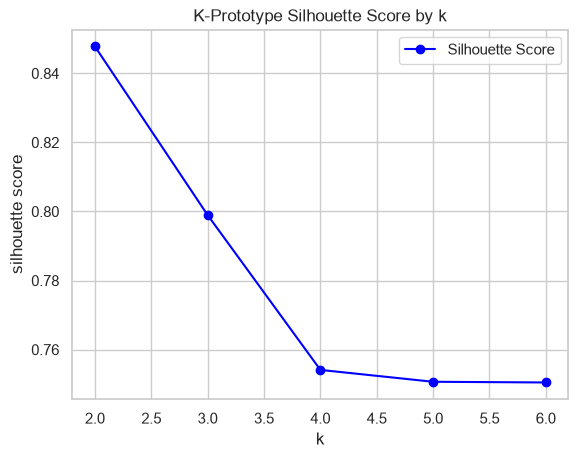

In [ ]:
# plot silhouette_results

ax = silhouette_results.plot(
    x='k', y='Silhouette Score', kind='line', marker='o', linestyle='-', color='blue'
)

ax.set_xlabel('k')
ax.set_ylabel('silhouette score')
ax.set_title('K-Prototype Silhouette Score by k')

plt.show()

After analyzing the data by cost of clustering through the elbow plot, the silhouette scores were calculated for k = 2-6 to see if a higher number of clusters would lead to greater separation. Clustering on k = 2 reduces the cost, but k = 4 clusters offers slightly better separation. Even though the difference in silhouette scores is minimal, there could still be value in investigating both clustering methods.

In [ ]:
# Fit to k = 2 clusters
kprototype2 = KPrototypes(n_jobs = -1, n_clusters = 2, init = 'Huang', random_state = 0)
k2pred = kprototype2.fit_predict(df2Matrix, categorical = catColumnsPos)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical).
# Towards Data Science.
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

In [ ]:
print("Clusters:", kprototype2.n_clusters)

# Cluster centorid
kprototype2.cluster_centroids_
print(kprototype2.cluster_centroids_)

# Check the iteration of the clusters created
kprototype2.n_iter_
print("Number of iterations:", kprototype2.n_iter_)

print("Cost:", kprototype2.cost_)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical).
# Towards Data Science.
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

Clusters: 2
[['21.122094198504143' '53.58139276329088' '975.975530624621' 'Male' 'No'
  'No' 'No' 'Yes' 'No' 'DSL' 'No' 'No' 'No' 'No' 'No' 'No'
  'Month-to-month' 'Yes' 'Electronic check']
 ['58.9212786259542' '91.14954675572545' '5356.878697519079' 'Female'
  'No' 'Yes' 'No' 'Yes' 'Yes' 'Fiber optic' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
  'Yes' 'Two year' 'Yes' 'Bank transfer (automatic)']]
Number of iterations: 6
Cost: 7953115004.732385


In [ ]:
# Fit to k = 4 clusters
kprototype4 = KPrototypes(n_jobs = -1, n_clusters = 4, init = 'Huang', random_state = 0)
kprototype4.fit_predict(df2Matrix, categorical = catColumnsPos)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical).
# Towards Data Science.
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

array([1, 1, 1, ..., 3, 1, 3], shape=(7043,), dtype=uint16)

In [ ]:
print("Clusters:", kprototype4.n_clusters)

# Cluster centorid
kprototype4.cluster_centroids_
print(kprototype4.cluster_centroids_)

# Check the iteration of the clusters created
kprototype4.n_iter_
print("Number of iterations:", kprototype4.n_iter_)

print("Cost:", kprototype4.cost_)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical).
# Towards Data Science.
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

Clusters: 4
[['37.42300884955752' '62.82716814159291' '1936.7170206489723' 'Male'
  'No' 'Yes' 'No' 'Yes' 'Yes' 'Fiber optic' 'No' 'No' 'No' 'No' 'No' 'No'
  'Month-to-month' 'Yes' 'Electronic check']
 ['11.993726474278544' '48.231602885821616' '422.30763801756194' 'Female'
  'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No'
  'Month-to-month' 'Yes' 'Mailed check']
 ['52.085930918281385' '82.6986941870262' '4171.905012636903' 'Male' 'No'
  'Yes' 'No' 'Yes' 'Yes' 'Fiber optic' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
  'Month-to-month' 'Yes' 'Electronic check']
 ['66.28571428571429' '100.40991778006159' '6654.743422404943' 'Female'
  'No' 'Yes' 'No' 'Yes' 'Yes' 'Fiber optic' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
  'Yes' 'Two year' 'Yes' 'Bank transfer (automatic)']]
Number of iterations: 20
Cost: 2135287208.7990336


In [ ]:
# Look at characteristics of the cluster centroids when k = 2

# Extract cluster centroids
centroids = kprototype2.cluster_centroids_

# Number of numerical columns
num_len = len(num_cols)

# Separate numerical and categorical centroids
num_centroids = centroids[:, :num_len]
cat_centroids = centroids[:, num_len:]

# Create DataFrames
df_num_centroids = pd.DataFrame(num_centroids, columns=num_cols)

df_cat_centroids = pd.DataFrame(cat_centroids, columns=cat_cols)

# Combine into one table
df_centroids2 = pd.concat([df_num_centroids, df_cat_centroids], axis=1)

# Add cluster labels
df_centroids2.index = [
    f"Cluster {i + 1}"
    for i in range(len(df_centroids2))
]

# Attach cluster assignments to original observations
df_eval2kx = df2.copy().reset_index(drop=True)
df_eval2kx = df_eval2kx.drop(columns = ["Churn Score", "CLTV", "Churn Reason"])
df_eval2kx['Cluster'] = kprototype2.labels_

# Calculate metrics
cluster_metrics2 = (
    df_eval2kx.groupby('Cluster')
    [['rf_prob', 'rf_pred', 'Churn Value']]
    .mean()
    .reindex([0, 1])
)

# Rename columns
cluster_metrics2.columns = [
    'Avg_RF_Probability',
    'Avg_RF_Prediction',
    'Actual_Churn_Rate'
]

# Reset centroid table index
df_centroids2 = df_centroids2.reset_index(drop=True)

# Assign metrics directly by row position
df_centroids2[cluster_metrics2.columns] = cluster_metrics2.to_numpy()

# Round numerical values to 2 decimal places
df_centroids2[num_cols] = df_centroids2[num_cols].astype(float).round(2)
df_centroids2[cluster_metrics2.columns] = (
    df_centroids2[cluster_metrics2.columns].round(2)
)

# Label clusters consistently
df_centroids2.index = ['Cluster 0', 'Cluster 1']

display(df_centroids2)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 16, 2026, from https://chatgpt.com/

,Tenure Months,Monthly Charges,Total Charges,Gender,Senior Citizen,Partner,Dependents,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Avg_RF_Probability,Avg_RF_Prediction,Actual_Churn_Rate
Cluster 0,21.120,53.580,975.980,Male,No,No,No,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,0.440,0.460,0.310
Cluster 1,58.920,91.150,5356.880,Female,No,Yes,No,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),0.280,0.240,0.150


In [ ]:
# attach k = 2 cluster labels to the original data

df_clustered2 = df2.copy().reset_index(drop=True)
df_clustered2['Cluster'] = kprototype2.labels_

# Calculate churn statistics by cluster
clustered_summary2 = df_clustered2.groupby('Cluster').agg(
    **{
    "Customer Count": ('Churn Value', 'size'),
    "Actual Churn Count": ('Churn Value', 'sum'),
    "Actual Churn Rate (%)": ('Churn Value', 'mean'),
    "Predicted Churn Count": ('rf_pred', 'sum'),
    "Predicted Churn Rate (%)": ('rf_pred', 'mean')
    }
)

# Convert rates to percentages
clustered_summary2[
    ['Actual Churn Rate (%)', 'Predicted Churn Rate (%)']
] *= 100

clustered_summary2 = clustered_summary2.round(1)

#display(clustered_summary2)

display(
    clustered_summary2.style.format({
        "Customer Count": "{:.0f}",
        "Actual Churn Count": "{:.0f}",
        "Actual Churn Rate (%)": "{:.1f}",
        "Predicted Churn Count": "{:.0f}",
        "Predicted Churn Rate (%)": "{:.1f}"
    })
)

,Customer Count,Actual Churn Count,Actual Churn Rate (%),Predicted Churn Count,Predicted Churn Rate (%)
Cluster,,,,,
0,4947,1547,31.3,2298,46.5
1,2096,322,15.4,493,23.5


This is a summary table of the clusters when k = 2. While there might be some separation in a few columns, such as total charges ($975.58 vs. $5356.88), there is no large separation in the actual churn rate, predicted churn rate, or the churn probability. These clusters did not achieve what we were hoping, which was to segregate the customers into a largely churn and no-churn groups.

In [ ]:
# Look at characteristics of the cluster centroids when k = 4

# Extract cluster centroids
centroids = kprototype4.cluster_centroids_

# Number of numerical columns
num_len = len(num_cols)

# Separate numerical and categorical centroids
num_centroids = centroids[:, :num_len]
cat_centroids = centroids[:, num_len:]

# Create DataFrames
df_num_centroids = pd.DataFrame(num_centroids, columns=num_cols)

df_cat_centroids = pd.DataFrame(cat_centroids, columns=cat_cols)

# Combine into one table
df_centroids4 = pd.concat([df_num_centroids, df_cat_centroids], axis=1)

# Add cluster labels
df_centroids4.index = [
    f"Cluster {i + 1}"
    for i in range(len(df_centroids4))
]

# Attach cluster assignments to original observations
df_eval4kx = df2.copy().reset_index(drop=True)
df_eval4kx = df_eval4kx.drop(columns = ["Churn Score", "CLTV", "Churn Reason"])
df_eval4kx['Cluster'] = kprototype4.labels_

# Calculate metrics
cluster_metrics4 = (
    df_eval4kx.groupby('Cluster')
    [['rf_prob', 'rf_pred', 'Churn Value']]
    .mean()
    .reindex([0, 1, 2, 3])
)

# Rename columns
cluster_metrics4.columns = [
    'Avg_RF_Probability',
    'Avg_RF_Prediction',
    'Actual_Churn_Rate'
]

# Reset centroid table index
df_centroids4 = df_centroids4.reset_index(drop=True)

# Assign metrics directly by row position
df_centroids4[cluster_metrics4.columns] = cluster_metrics4.to_numpy()

# Round numerical values to 2 decimal places
df_centroids4[num_cols] = df_centroids4[num_cols].astype(float).round(2)
df_centroids4[cluster_metrics4.columns] = (
    df_centroids4[cluster_metrics4.columns].round(2)
)

# Label clusters consistently
df_centroids4.index = ['Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3']

display(df_centroids4)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 16, 2026, from https://chatgpt.com/

,Tenure Months,Monthly Charges,Total Charges,Gender,Senior Citizen,Partner,Dependents,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Avg_RF_Probability,Avg_RF_Prediction,Actual_Churn_Rate
Cluster 0,37.420,62.830,1936.720,Male,No,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,0.350,0.340,0.230
Cluster 1,11.990,48.230,422.310,Female,No,No,No,Yes,No,No,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,0.490,0.530,0.360
Cluster 2,52.090,82.700,4171.910,Male,No,Yes,No,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,0.310,0.280,0.170
Cluster 3,66.290,100.410,6654.740,Female,No,Yes,No,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),0.250,0.180,0.130


In [ ]:
# attach k = 4 cluster labels to the original data

df_clustered4 = df2.copy().reset_index(drop=True)
df_clustered4['Cluster'] = kprototype4.labels_

# Calculate churn statistics by cluster
clustered_summary4 = df_clustered4.groupby('Cluster').agg(
    **{
    "Customer Count": ('Churn Value', 'size'),
    "Actual Churn Count": ('Churn Value', 'sum'),
    "Actual Churn Rate (%)": ('Churn Value', 'mean'),
    "Predicted Churn Count": ('rf_pred', 'sum'),
    "Predicted Churn Rate (%)": ('rf_pred', 'mean')
    }
)

# Convert rates to percentages
clustered_summary4[
    ['Actual Churn Rate (%)', 'Predicted Churn Rate (%)']
] *= 100

clustered_summary4 = clustered_summary4.round(1)

#display(clustered_summary4)

display(
    clustered_summary4.style.format({
        "Customer Count": "{:.0f}",
        "Actual Churn Count": "{:.0f}",
        "Actual Churn Rate (%)": "{:.1f}",
        "Predicted Churn Count": "{:.0f}",
        "Predicted Churn Rate (%)": "{:.1f}"
    })
)

,Customer Count,Actual Churn Count,Actual Churn Rate (%),Predicted Churn Count,Predicted Churn Rate (%)
Cluster,,,,,
0,1695,385,22.7,582,34.3
1,3188,1150,36.1,1698,53.3
2,1187,205,17.3,336,28.3
3,973,129,13.3,175,18.0


There was a chance that additional clusters might provide more opportunities for concentrating churners into a group compared to two clusters. However, that was not the case. Similar to the k = 2 model, the cluster sizes were somewhat balanced with some separation within the category groups. However, again, there was no one cluster with a high churn actual or predicted churn rate.

In [ ]:
# order the cluster

dfk2 = df_clustered2.copy()
dfk2['Cluster'] = dfk2['Cluster'].astype('category')

dfk4 = df_clustered4.copy()
dfk4['Cluster'] = dfk4['Cluster'].astype('category')

#dfk4.head()

In [ ]:
# look at overall purity across multiple columns, k = 2

purity_by_column2 = {}

columns_to_check = dfk2.drop(columns = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "Cluster"])

for col in columns_to_check:
    table = pd.crosstab(dfk2['Cluster'], dfk2[col])

    purity_by_column2[col] = (
        table.max(axis=1).sum() / table.values.sum()
        if table.values.sum() > 0 else 0
    )

overall_purity2 = sum(purity_by_column2.values()) / len(purity_by_column2)

print(f"\nAverage overall purity, k = 2: {overall_purity2:.2%}")

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/


Average overall purity, k = 2: 52.04%


In [ ]:
# look at overall purity across multiple columns, k = 4

purity_by_column4 = {}

columns_to_check = dfk4.drop(columns = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "Cluster"])

for col in columns_to_check:
    table = pd.crosstab(dfk4['Cluster'], dfk4[col])

    purity_by_column4[col] = (
        table.max(axis=1).sum() / table.values.sum()
        if table.values.sum() > 0 else 0
    )

overall_purity4 = sum(purity_by_column4.values()) / len(purity_by_column4)

print(f"\nAverage overall purity, k = 4: {overall_purity4:.2%}")

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/


Average overall purity, k = 4: 52.54%


Even though the clusters did not concentrate the churners, the purity of the clusters was assessed for completion. Given that the silhouette scores were so close, it is not surprising that the purity scores are also similar.

In [ ]:
# look at column purity by each cluster, k = 2

# Specify categorical columns to evaluate
columns_to_check = dfk2.drop(columns = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "Cluster"])

purityk_results2 = []

for col in columns_to_check:
    row = {'Feature': col}

    for cluster in [0, 1]:
        subset = dfk2[dfk2['Cluster'] == cluster]
        counts = subset[col].value_counts() # count of most frequent category

        row[f'Cluster {cluster} Majority'] = (
            counts.idxmax() if not counts.empty else None
        )
        row[f'Cluster {cluster} Purity'] = (
            counts.max() / len(subset) if len(subset) and not counts.empty else 0 # total observations in cluster
        )

    purityk_results2.append(row)

df_purityk_wide2 = pd.DataFrame(purityk_results2)

purity_cols2 = [
    'Cluster 0 Purity',
    'Cluster 1 Purity',
    'Combined Purity, k = 2'
]

# Format purity as percentages
df_purityk_wide2['Cluster 0 Purity'] = (
    df_purityk_wide2['Cluster 0 Purity']
)

df_purityk_wide2['Cluster 1 Purity'] = (
    df_purityk_wide2['Cluster 1 Purity']
)

combined_purity2 = []

for col in columns_to_check:
    table = pd.crosstab(dfk2['Cluster'], dfk2[col])

    purity = table.max(axis=1).sum() / table.values.sum()

    combined_purity2.append(purity)

df_purityk_wide2['Combined Purity, k = 2'] = combined_purity2

df_purityk_wide2[purity_cols2] = (
    df_purityk_wide2[purity_cols2] * 100
).round(1)

display(df_purityk_wide2)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

,Feature,Cluster 0 Majority,Cluster 0 Purity,Cluster 1 Majority,Cluster 1 Purity,"Combined Purity, k = 2"
0,Gender,Male,50.700,Female,50.000,50.500
1,Senior Citizen,No,85.900,No,78.800,83.800
2,Partner,No,60.200,Yes,68.500,62.700
3,Dependents,No,77.300,No,75.900,76.900
4,Tenure Months,1,12.400,72,14.000,12.900
5,Phone Service,Yes,88.200,Yes,95.400,90.300
6,Multiple Lines,No,58.700,Yes,72.300,62.800
7,Internet Service,DSL,34.800,Fiber optic,66.700,44.300
8,Online Security,No,51.300,Yes,54.200,52.100
9,Online Backup,No,48.600,Yes,67.400,54.200


In [ ]:
# look at column purity by each cluster, k = 4

# Specify categorical columns to evaluate
columns_to_check = dfk4.drop(columns = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "Cluster"])

purityk_results4 = []

for col in columns_to_check:
    row = {'Feature': col}

    for cluster in [0, 1, 2, 3]:
        subset = dfk4[dfk4['Cluster'] == cluster]
        counts = subset[col].value_counts() # count of most frequent category

        row[f'Cluster {cluster} Majority'] = (
            counts.idxmax() if not counts.empty else None
        )
        row[f'Cluster {cluster} Purity'] = (
            counts.max() / len(subset) if len(subset) and not counts.empty else 0 # total observations in cluster
        )

    purityk_results4.append(row)

df_purityk_wide4 = pd.DataFrame(purityk_results4)

purity_cols4 = [
    'Cluster 0 Purity',
    'Cluster 1 Purity',
    'Cluster 2 Purity',
    'Cluster 3 Purity',
    'Combined Purity, k = 4'
]

# Format purity as percentages
df_purityk_wide4['Cluster 0 Purity'] = (
    df_purityk_wide4['Cluster 0 Purity']
)

df_purityk_wide4['Cluster 1 Purity'] = (
    df_purityk_wide4['Cluster 1 Purity']
)

df_purityk_wide4['Cluster 2 Purity'] = (
    df_purityk_wide4['Cluster 2 Purity']
)

df_purityk_wide4['Cluster 3 Purity'] = (
    df_purityk_wide4['Cluster 3 Purity']
)

combined_purity4 = []

for col in columns_to_check:
    table = pd.crosstab(dfk4['Cluster'], dfk4[col])

    purity = table.max(axis=1).sum() / table.values.sum()

    combined_purity4.append(purity)

df_purityk_wide4['Combined Purity, k = 4'] = combined_purity4

df_purityk_wide4[purity_cols4] = (
    df_purityk_wide4[purity_cols4] * 100
).round(1)

display(df_purityk_wide4)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

,Feature,Cluster 0 Majority,Cluster 0 Purity,Cluster 1 Majority,Cluster 1 Purity,Cluster 2 Majority,Cluster 2 Purity,Cluster 3 Majority,Cluster 3 Purity,"Combined Purity, k = 4"
0,Gender,Male,52.500,Female,50.400,Male,50.700,Female,50.600,51.000
1,Senior Citizen,No,82.300,No,87.900,No,79.400,No,78.300,83.800
2,Partner,Yes,52.900,No,67.600,Yes,61.600,Yes,76.200,64.200
3,Dependents,No,76.500,No,77.900,No,76.900,No,74.200,76.900
4,Tenure Months,72,4.000,1,19.200,72,4.500,72,24.800,13.800
5,Phone Service,Yes,86.500,Yes,89.100,Yes,91.000,Yes,100.000,90.300
6,Multiple Lines,Yes,44.900,No,68.100,Yes,59.800,Yes,85.400,63.500
7,Internet Service,Fiber optic,40.500,No,37.100,Fiber optic,53.800,Fiber optic,81.300,46.900
8,Online Security,No,51.200,No,51.300,No,51.100,Yes,59.800,52.400
9,Online Backup,No,47.000,No,49.500,Yes,57.900,Yes,78.000,54.200


This data looks at each cluster and measures the purity or homogeneity of the most frequent category for each column. When looking at the Churn Value, the majority in all clusters, when k = 2 and k = 4, are non-churners. Additionally, the majority in the random forests-generated prediction are also non-churners in both the k = 2 and k = 4 models. The majority of cluster purity measures are similar or even between the clusters, suggesting that they are not strong indicators. For example, when examining gender in the k = 2, 50% of Cluster 0 are men and 50.5% of Cluster 1 are women. This gender distribution is also observed in the k = 4 model. Therefore, gender is not a strong predictor of clustering. Similarly, approximately 90% of customers have phone service in all clusters across the k = 2 and k = 4 models. Again, this similarity is not useful in distinguishing between clusters. Ultimately, this clustering endeavor has failed.

The purity of the demographic features are fairly uniform across all clusters in the k = 2 and k = 4 model. However, the package and purchasing data may show greater separation. Therefore, the clustering process will be repeated focusing only on the customer packages and purchases.

In [ ]:
# prepare data frame for clustering

df2kx_nd = df2.copy()

df2kx_nd = df2kx_nd.drop(columns = ["Gender", "Senior Citizen", "Partner", "Dependents", "Churn Value", "Churn Score", "CLTV", "Churn Reason", "rf_prob", "rf_pred"])

df2kx_nd.head()

,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
0,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150
1,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.650
2,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.650,820.500
3,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.800,3046.050
4,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.700,5036.300


In [ ]:
# index the columns based on position

catColumnsPos_nd = [df2kx_nd.columns.get_loc(col) for col in list(df2kx_nd.select_dtypes('object').columns)]
print('Categorical columns           : {}'.format(list(df2kx_nd.select_dtypes('object').columns)))
print('Categorical columns position  : {}'.format(catColumnsPos_nd))

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical).
# Towards Data Science.
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

Categorical columns           : ['Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']
Categorical columns position  : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


C:\Users\mlmug\AppData\Local\Temp\ipykernel_22000\2547410294.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
C:\Users\mlmug\AppData\Local\Temp\ipykernel_22000\2547410294.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes f

In [ ]:
# convert data frame to a matrix

df2Matrix_nd = df2kx_nd.to_numpy()

Cluster initiation: 1
Cluster initiation: 2
Cluster initiation: 3
Cluster initiation: 4
Cluster initiation: 5
Cluster initiation: 6
Cluster initiation: 7
Cluster initiation: 8
Cluster initiation: 9


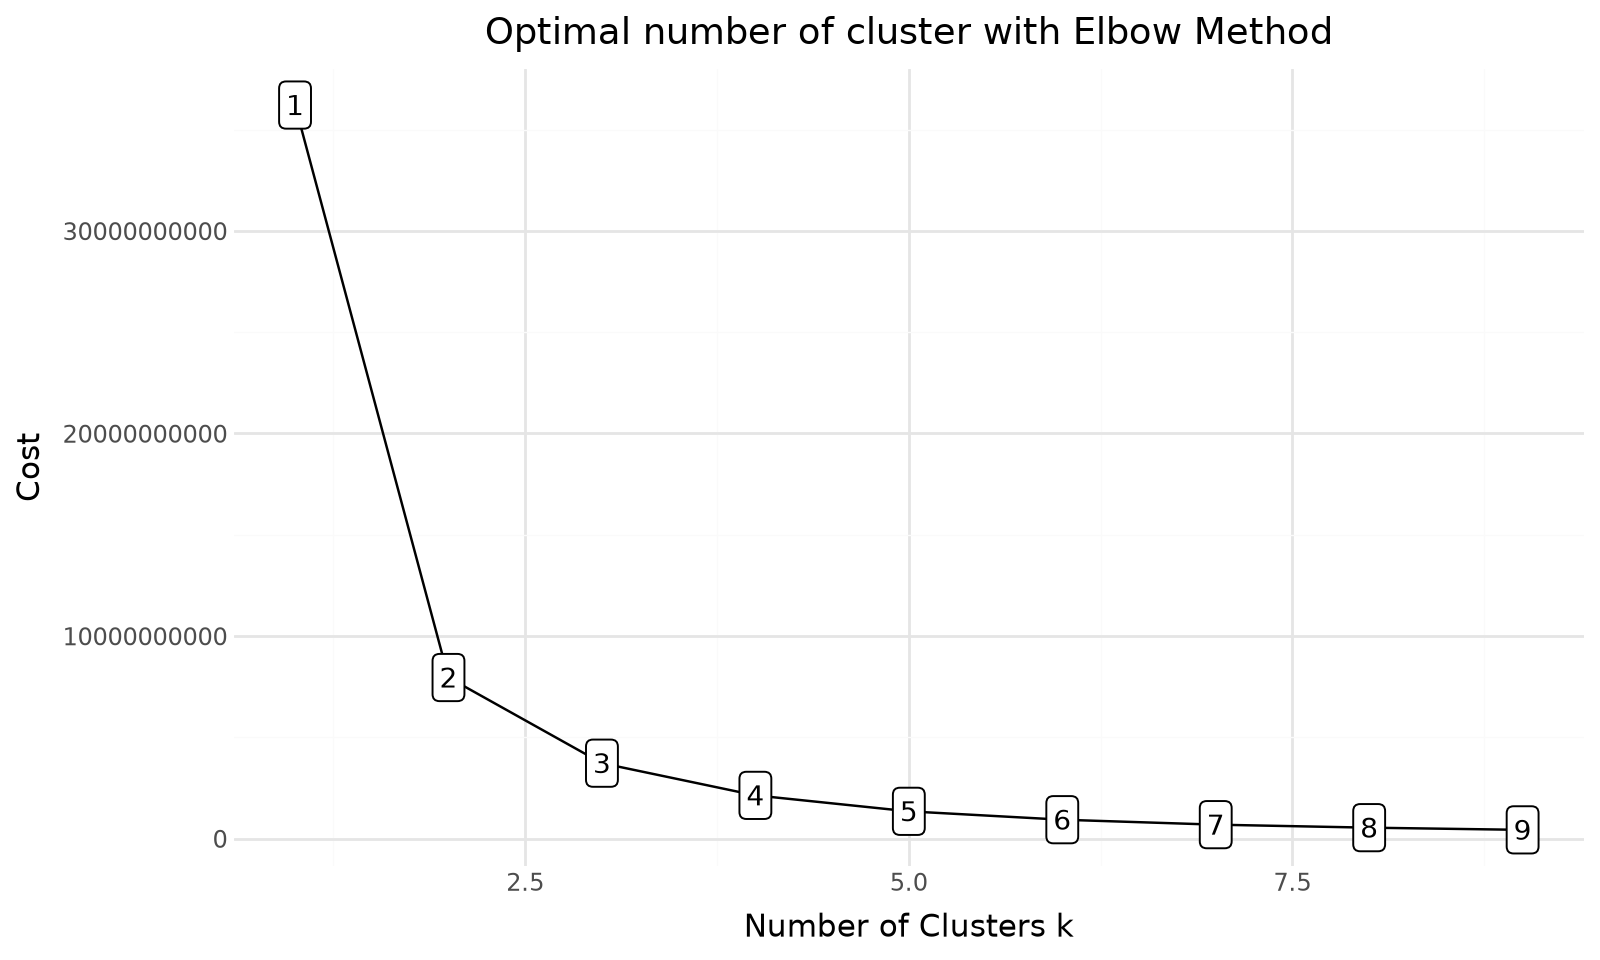

In [ ]:
# Choose optimal K using Elbow method

cost = []

for cluster in range(1, 10):
    try:
        kprototype_nd = KPrototypes(n_jobs = -1, n_clusters = cluster, init = 'Huang', random_state = 0)
        kprototype_nd.fit_predict(df2Matrix_nd, categorical = catColumnsPos_nd)
        cost.append(kprototype_nd.cost_)
        print('Cluster initiation: {}'.format(cluster))
    except:
        break
# Converting the results into a dataframe and plotting them
df2_cost_nd = pd.DataFrame({'Cluster':range(1, 10), 'Cost':cost})
# Data viz
plotnine.options.figure_size = (8, 4.8)
(
    ggplot(data = df2_cost_nd)+
    geom_line(aes(x = 'Cluster',
                  y = 'Cost'))+
    geom_point(aes(x = 'Cluster',
                   y = 'Cost'))+
    geom_label(aes(x = 'Cluster',
                   y = 'Cost',
                   label = 'Cluster'),
               size = 10,
               nudge_y = 1000) +
    labs(title = 'Optimal number of cluster with Elbow Method')+
    xlab('Number of Clusters k')+
    ylab('Cost')+
    theme_minimal()
)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical).
# Towards Data Science.
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

k = 2 clusters provided a strong starting point.

In [ ]:
# calculate silhouette scores for each model

silhouette_scores_nd = {}

# create mixed-data distance matrix
def create_dm_nd(dataset, categorical, gamma):
    total_nd = len(dataset)
    distance_matrix_nd = np.zeros((total_nd, total_nd))

    categorical = set(categorical)
    numerical = [
        i for i in range(dataset.shape[1])
        if i not in categorical
    ]

    for i in range(total_nd):
        for j in range(i + 1, total_nd):
            num_dist = sum(
                (float(dataset[i, col]) - float(dataset[j, col])) ** 2
                for col in numerical
            )

            cat_dist = sum(
                dataset[i, col] != dataset[j, col]
                for col in categorical
            )

            distance = num_dist + gamma * cat_dist
            distance_matrix_nd[i, j] = distance
            distance_matrix_nd[j, i] = distance

    return distance_matrix_nd

# Use your existing matrix and model
X_nd = np.asarray(df2Matrix_nd)
gamma_nd = kprototype_nd.gamma

distance_matrix_nd = create_dm_nd(
    X_nd,
    catColumnsPos_nd,
    gamma_nd
)

# k = 2
kprototype2_nd = KPrototypes(n_jobs=-1, n_clusters=2, init="Huang", random_state=0)
k2pred_nd = kprototype2_nd.fit_predict(df2Matrix_nd, categorical=catColumnsPos_nd)
silhouette_scores_nd[2] = silhouette_score(distance_matrix_nd, k2pred_nd, metric="precomputed")

# k = 3
kprototype3_nd = KPrototypes(n_jobs=-1, n_clusters=3, init="Huang", random_state=0)
k3pred_nd = kprototype3_nd.fit_predict(df2Matrix_nd, categorical=catColumnsPos_nd)
silhouette_scores_nd[3] = silhouette_score(distance_matrix_nd, k3pred_nd, metric="precomputed")

# k = 4
kprototype4_nd = KPrototypes(n_jobs=-1, n_clusters=4, init="Huang", random_state=0)
k4pred_nd = kprototype4_nd.fit_predict(df2Matrix_nd, categorical=catColumnsPos_nd)
silhouette_scores_nd[4] = silhouette_score(distance_matrix_nd, k4pred_nd, metric="precomputed")

# k = 5
kprototype5_nd = KPrototypes(n_jobs=-1, n_clusters=5, init="Huang", random_state=0)
k5pred_nd = kprototype5_nd.fit_predict(df2Matrix_nd, categorical=catColumnsPos_nd)
silhouette_scores_nd[5] = silhouette_score(distance_matrix_nd, k5pred_nd, metric="precomputed")

# k = 6
kprototype6_nd = KPrototypes(n_jobs=-1, n_clusters=6, init="Huang", random_state=0)
k6pred_nd = kprototype6_nd.fit_predict(df2Matrix_nd, categorical=catColumnsPos_nd)
silhouette_scores_nd[6] = silhouette_score(distance_matrix_nd, k6pred_nd, metric="precomputed")


# Display results
print("The k and associated Silhouette scores are:", silhouette_scores_nd)

silhouette_results_nd = pd.DataFrame(
    list(silhouette_scores_nd.items()),
    columns=["k", "Silhouette Score"]
)

display(silhouette_results_nd)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 16, 2026, from https://chatgpt.com/

# Staff, C. (2022, December 2). Silhouette coefficient for k-modes and k-prototypes clustering. Coding Infinite.
# https://codinginfinite.com/silhouette-coefficient-for-k-modes-and-k-prototypes-clustering/

The k and associated Silhouette scores are: {2: 0.8478114583951881, 3: 0.7990864276591024, 4: 0.7542800886847351, 5: 0.7519209056102047, 6: 0.7499025588272122}


,k,Silhouette Score
0,2,0.848
1,3,0.799
2,4,0.754
3,5,0.752
4,6,0.750


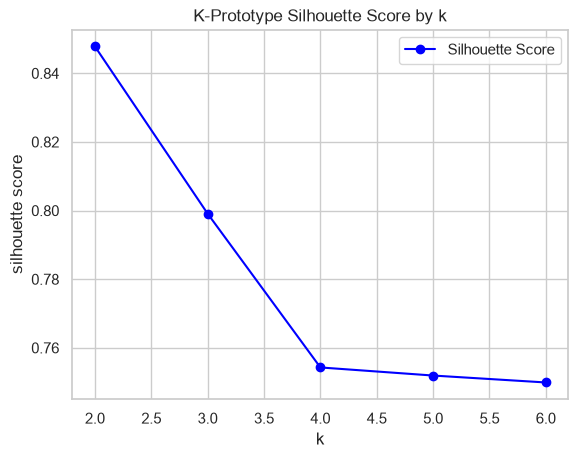

In [ ]:
# plot silhouette_results

ax = silhouette_results_nd.plot(
    x='k', y='Silhouette Score', kind='line', marker='o', linestyle='-', color='blue'
)

ax.set_xlabel('k')
ax.set_ylabel('silhouette score')
ax.set_title('K-Prototype Silhouette Score by k')

plt.show()

The silhouette scores of the data set without demographic information is nearly identical to the silhouette scores from the data set that included the demographic information. So, I probed further to ensure that the code was written properly.

In [ ]:
# 1. Compare dataset dimensions
print("Original shape:", np.asarray(df2Matrix).shape)
print("New shape:", np.asarray(df2Matrix_nd).shape)

# 2. Compare the number of categorical columns
print("Original categorical columns:", len(catColumnsPos))
print("New categorical columns:", len(catColumnsPos_nd))

# 3. Compare gamma
print("Original gamma:", kprototype.gamma)
print("New gamma:", kprototype_nd.gamma)

Original shape: (7043, 19)
New shape: (7043, 15)
Original categorical columns: 16
New categorical columns: 12
Original gamma: 386.8798644841518
New gamma: 386.8798644841518


In [ ]:
print(
    "Minimum distance difference:",
    np.min(np.abs(distance_matrix - distance_matrix_nd))
)

print(
    "Distance matrices identical:",
    np.allclose(distance_matrix, distance_matrix_nd)
)

print(
    "Maximum distance difference:",
    np.max(np.abs(distance_matrix - distance_matrix_nd))
)

Minimum distance difference: 0.0
Distance matrices identical: False
Maximum distance difference: 1547.5194579437375


In [ ]:
for k in silhouette_scores:
    print(
        f"k={k}: "
        f"original={silhouette_scores[k]:.12f}, "
        f"new={silhouette_scores_nd[k]:.12f}"
    )

k=2: original=0.847785241900, new=0.847811458395
k=3: original=0.798942264337, new=0.799086427659
k=4: original=0.754111640682, new=0.754280088685
k=5: original=0.750675620272, new=0.751920905610
k=6: original=0.750473770830, new=0.749902558827


This analysis showed that the demographic information did not have great influence on the original clustering effort. Removing the demographic data from the data set, ultimately, did not lead to changes in the cost of clustering or improve the separation of the clusters. Finally, this marked the end of the clustering efforts.

## Identifying Customer Types via Association Rules

Clustering did not yield any usable methods for grouping the customers, association rules were explored.

In [ ]:
# create association rules, support of 2% and confidence of 70% were pre-selected parameters.

df2a = df2.copy()
df2a = df2a.drop(columns = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "rf_pred"])

target = "Churn Value"
cat_cols = ["Gender", "Senior Citizen", "Partner", "Dependents", "Phone Service", "Multiple Lines", "Internet Service",
"Online Security", "Online Backup", "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies", "Contract",
"Paperless Billing", "Payment Method"]
num_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]

# Convert numerical variables to categorical intervals
for col in num_cols:
    df2a[col] = pd.qcut(
        df2a[col],
        q=4,
        duplicates="drop"
    )

# Convert predictors into categorical indicator variables
X = pd.get_dummies(
    df2a[cat_cols + num_cols].astype(str),
    dtype=bool
)

# Add the binary response as an item
X["Churn=1"] = df2a[target].eq(1)
X["Churn=0"] = df2a[target].eq(0)

# Find frequent itemsets
itemsets = apriori(
    X,
    min_support=0.02, # retain itemsets that appear in at least 2% of observations
    use_colnames=True,
    max_len=3 # consider itemsets containing up to 3 items
)

# Generate association rules
rules = association_rules(
    itemsets,
    metric="confidence",
    min_threshold=0.7 # retain rules with at least 70% confidence
)

# Retain only rules predicting Churn=1
positive_rules = rules[
    rules["consequents"].apply(
        lambda s: s == frozenset(["Churn=1"])
    )
]

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)


positive_rules.sort_values(
        "lift", ascending=False
    )[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].head(40)

# Shmueli, G., Bruce, P. C., Gedeck, P., & Patel, N. R. (2025). Machine learning for business analytics (2nd ed.).
# Wiley-Blackwell. https://bookshelf.vitalsource.com/books/9781394286805

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

,antecedents,consequents,support,confidence,lift
6936,"frozenset({Total Charges_(-0.001, 398.55], Internet Service_Fiber optic})",frozenset({Churn=1}),0.056,0.749,2.823
10087,"frozenset({Total Charges_(-0.001, 398.55], Monthly Charges_(70.35, 89.85]})",frozenset({Churn=1}),0.037,0.737,2.776
6914,"frozenset({Internet Service_Fiber optic, Tenure Months_(-0.001, 9.0]})",frozenset({Churn=1}),0.080,0.711,2.678


In [ ]:
# total number of rules
print("Total rules:", len(rules))

# total number of rules predicting churn
print("Churn rules:", len(positive_rules))

# total number of rules with confidence >= 0.70 and lift >= 1.5
filtered_rules = positive_rules[
    (positive_rules["confidence"] >= 0.70) &
    (positive_rules["lift"] >= 1.5)
]

print("Filtered churn rules:", len(filtered_rules))

Total rules: 10092
Churn rules: 3
Filtered churn rules: 3


The analysis via association has revealed 3 rules with low support (<0.1), high confidence (>0.70), and high lift (>2). This suggests that these rules are specific enough that the combination of the listed variables in the antecedent leads to a consequent of churn = 1.

In [ ]:
# summary of rule ID groups

target = "Churn Value"

# Overall churn rate
baseline_churn = df2a[target].mean()

# Store customer subsets for each rule
rule_subsets = {}
rule_summary = []

for idx, rule in positive_rules.iterrows():

    # Identify the predictor items in the antecedent
    antecedent = rule["antecedents"]

    # Match customers who satisfy ALL antecedent items
    mask = X[list(antecedent)].all(axis=1)

    # Subset the original customer data
    subset = df2a.loc[mask].copy()
    subset["rf_pred"] = df2.loc[mask, "rf_pred"]

    rule_subsets[idx] = subset

    # Calculate actual churn metrics
    n_customers = len(subset)
    actual_churners = subset[target].sum()

    actual_churn_rate = (
        subset[target].mean() if n_customers > 0 else np.nan
    )

    # Rule confidence = estimated churn probability for this segment
    predicted_churn_rate = subset["rf_pred"].mean()

    rule_summary.append({
        "rule_id": idx,
        "antecedents": antecedent,
        "support": rule["support"],
        "confidence": rule["confidence"],
        "association_lift": rule["lift"],
        "customers": n_customers,
        "customer_share": n_customers / len(df2a),
        "actual_churners": actual_churners,
        "actual_churn_rate": actual_churn_rate,
        "predicted_churn_rate": predicted_churn_rate,
        "actual_churn_lift": (
            actual_churn_rate / baseline_churn
            if baseline_churn > 0 else np.nan
        )
    })

rule_summary = pd.DataFrame(rule_summary)

rule_summary = rule_summary.sort_values(
    "association_lift",
    ascending=False
)

rule_summary.head(40)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 18, 2026, from https://chatgpt.com/

,rule_id,antecedents,support,confidence,association_lift,customers,customer_share,actual_churners,actual_churn_rate,predicted_churn_rate,actual_churn_lift
1,6936,"frozenset({Total Charges_(-0.001, 398.55], Internet Service_Fiber optic})",0.056,0.749,2.823,530,0.075,397,0.749,0.989,2.823
2,10087,"frozenset({Total Charges_(-0.001, 398.55], Monthly Charges_(70.35, 89.85]})",0.037,0.737,2.776,353,0.050,260,0.737,0.966,2.776
0,6914,"frozenset({Internet Service_Fiber optic, Tenure Months_(-0.001, 9.0]})",0.080,0.711,2.678,788,0.112,560,0.711,0.982,2.678


This summary table confirms that the association rules are specific and effective in identifying customers with high churn rates.

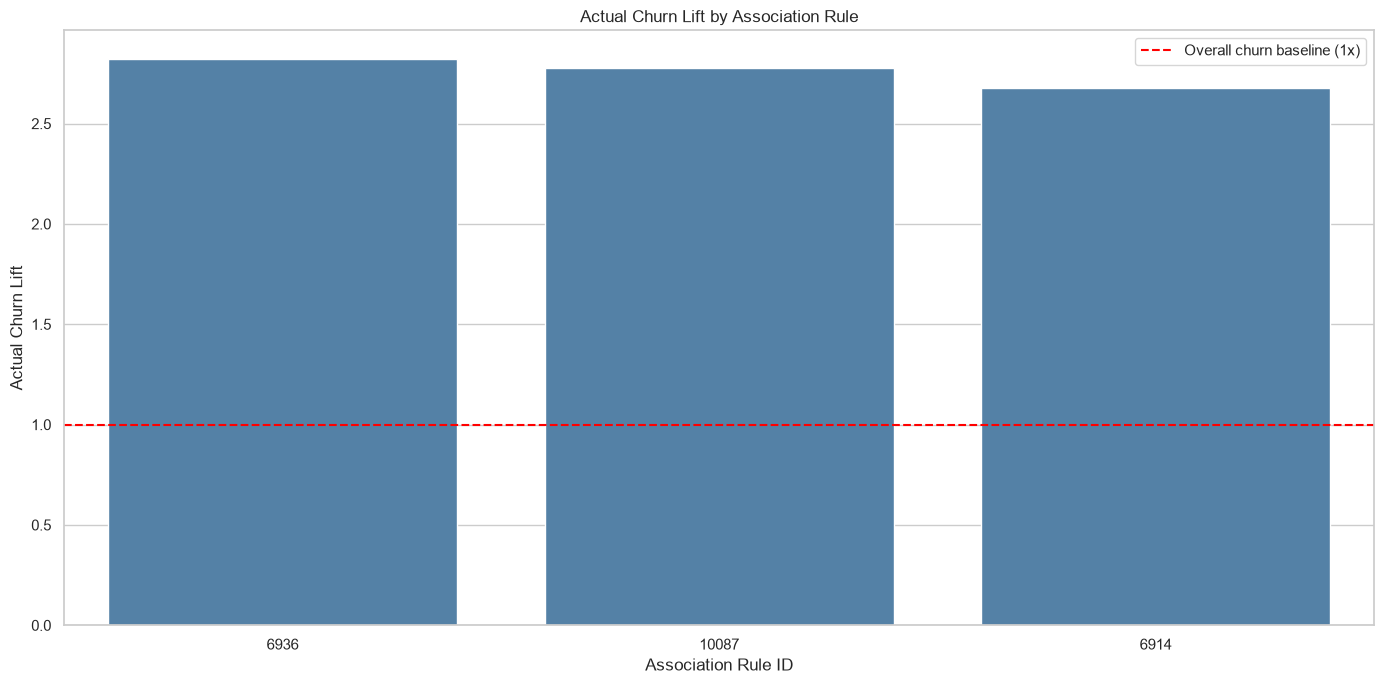

In [ ]:
# plotting lift of churn rates using association rules

plot_df = (
    rule_summary
    .sort_values("actual_churn_lift", ascending=False)
    .head(20)
    .copy()
)

plot_df["rule_label"] = plot_df["rule_id"].astype(str)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=plot_df,
    x="rule_label",
    y="actual_churn_lift",
    color="steelblue"
)

plt.axhline(
    1,
    color="red",
    linestyle="--",
    label="Overall churn baseline (1x)"
)

plt.xlabel("Association Rule ID")
plt.ylabel("Actual Churn Lift")
plt.title("Actual Churn Lift by Association Rule")
plt.legend()
plt.tight_layout()
plt.show()

This lift chart visualizes the lift from each association rule.

In [ ]:
# create a new data frame to evaluate churners within the association rule groups

df2a2 = df2a.copy()

cols_to_restore = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "rf_pred"]

df2a2[cols_to_restore] = df2.loc[df2a2.index, cols_to_restore]

# Initialize a rule_id list for every customer
df2a2["rule_id"] = [[] for _ in range(len(df2a2))]

for idx, rule in positive_rules.iterrows():

    antecedent = rule["antecedents"]
    mask = X[list(antecedent)].all(axis=1)

    # Add the rule ID to each matching customer
    for customer_idx in df2a2.index[mask]:
        df2a2.at[customer_idx, "rule_id"].append(idx)

#df2a2.head()

# Chatgpt. (n.d.). ChatGPT. Retrieved October 18, 2026, from https://chatgpt.com/

In [ ]:
# summary of association rule groups against all available columns in original data frame

# 1. Expand the rule ID lists
df_rules = df2a2.explode("rule_id").dropna(subset=["rule_id"]).copy()

# df_rules should already be exploded by rule_id

def mode_and_proportion(series):
    s = series.dropna()

    if s.empty:
        return pd.Series({
            "mode": np.nan,
            "mode_proportion": np.nan
        })

    counts = s.value_counts()
    return pd.Series({
        "mode": counts.index[0],
        "mode_proportion": counts.iloc[0] / len(s)
    })

# 2. Identify numeric and categorical columns
numeric_cols = [
    c for c in df_rules.select_dtypes(include="number").columns
    if c != "rule_id"
]

categorical_cols = [
    c for c in df_rules.select_dtypes(
        include=["object", "category", "bool", "string"]
    ).columns
    if c != "rule_id"
]

# 3. Numerical summaries: mean and median
numeric_summary = df_rules.groupby("rule_id")[numeric_cols].agg(
    ["mean", "median"]
)

# 4. Categorical mode
def get_mode(s):
    modes = s.mode(dropna=True)
    return modes.iloc[0] if not modes.empty else np.nan

categorical_modes = df_rules.groupby("rule_id")[categorical_cols].agg(
    get_mode
)

# 5. Categorical mode proportion
def get_mode_proportion(s):
    s = s.dropna()
    if s.empty:
        return np.nan

    return s.value_counts().iloc[0] / len(s)

categorical_proportions = df_rules.groupby("rule_id")[categorical_cols].agg(
    get_mode_proportion
)

# 6. Put mode and mode proportion next to each other per column
categorical_summary = pd.concat(
    {
        col: pd.DataFrame({
            "mode": categorical_modes[col],
            "mode_proportion": categorical_proportions[col]
        })
        for col in categorical_cols
    },
    axis=1
)

# Calculate mode and proportion for each categorical column
categorical_results = []

for col in categorical_cols:
    result = (
        df_rules.groupby("rule_id")[col]
        .apply(mode_and_proportion)
        .unstack()
    )

    result.columns = pd.MultiIndex.from_product(
        [[col], result.columns]
    )

    categorical_results.append(result)

categorical_summary = pd.concat(categorical_results, axis=1)

# Combine with your existing numerical summary
rule_summary_stats = pd.concat(
    [numeric_summary, categorical_summary],
    axis=1
)

# 7. Combine numerical and categorical summaries
rule_summary_stats = pd.concat(
    [numeric_summary, categorical_summary],
    axis=1
)

# 8. Add customer count for each rule
rule_summary_stats.insert(
    0,
    ("customer_count", ""),
    df_rules.groupby("rule_id").size()
)

# 9. Sort and display
rule_summary_stats = rule_summary_stats.sort_index(axis=1, level=0)

display(rule_summary_stats)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 18, 2026, from https://chatgpt.com/

CLTV                                        Churn Reason  \
            mean   median                                       mode   
rule_id                                                                
6914    3991.972 4033.000                 Attitude of support person   
6936    3993.819 4062.500  Competitor offered higher download speeds   
10087   3999.422 4054.000                 Attitude of support person   

                        Churn Score        Churn Value               Contract  \
        mode_proportion        mean median        mean median            mode   
rule_id                                                                         
6914              0.093      72.750 76.000       0.711  1.000  Month-to-month   
6936              0.101      73.504 77.000       0.749  1.000  Month-to-month   
10087             0.119      72.938 76.000       0.737  1.000  Month-to-month   

                        Dependents                 Device Protection  \
        mode_proportion       mode mode_proportion              mode   
rule_id                                                                
6914              0.996         No           0.938                No   
6936              1.000         No           0.942                No   
10087             0.989         No           0.935                No   

                         Gender                 Internet Service  \
        mode_proportion    mode mode_proportion             mode   
rule_id                                                            
6914              0.810  Female           0.534      Fiber optic   
6936              0.851  Female           0.542      Fiber optic   
10087             0.836  Female           0.564      Fiber optic   

                        Monthly Charges                 Multiple Lines  \
        mode_proportion            mode mode_proportion           mode   
rule_id                                                                  
6914              1.000  (70.35, 89.85]           0.631             No   
6936              1.000  (70.35, 89.85]           0.642             No   
10087             0.963  (70.35, 89.85]           1.000             No   

                        Online Backup                 Online Security  \
        mode_proportion          mode mode_proportion            mode   
rule_id                                                                 
6914              0.621            No           0.827              No   
6936              0.670            No           0.851              No   
10087             0.637            No           0.833              No   

                        Paperless Billing                 Partner  \
        mode_proportion              mode mode_proportion    mode   
rule_id                                                             
6914              0.921               Yes           0.780      No   
6936              0.932               Yes           0.758      No   
10087             0.921               Yes           0.737      No   

                           Payment Method                 Phone Service  \
        mode_proportion              mode mode_proportion          mode   
rule_id                                                                   
6914              0.756  Electronic check           0.694           Yes   
6936              0.774  Electronic check           0.717           Yes   
10087             0.796  Electronic check           0.674           Yes   

                        Senior Citizen                 Streaming Movies  \
        mode_proportion           mode mode_proportion             mode   
rule_id                                                                   
6914              1.000             No           0.745               No   
6936              1.000             No           0.745               No   
10087             1.000             No           0.748               No   

                        Streaming TV             

These association rules are quite effective at concentrating high-churn customers. The mean Churn Values (actual churn rates) are greater than 0.7 and the predicted churn rates are  greater than 0.9 in all association rule groups. Additionally, all of the groups and group proportions are quite similar across all three association rules. The association rules could prove to provide high-churn customer characteristics more efficiently than clustering.

In [ ]:
# customers who match or do not match at least one positive association rule

in_rules = df2a2[
    df2a2["rule_id"].apply(lambda ids: len(ids) > 0)
].copy()

# Customers who match no positive association rules
outside_rules = df2a2[
    df2a2["rule_id"].apply(lambda ids: len(ids) == 0)
].copy()

# Compare the two groups with the overall population
comparison = pd.DataFrame({
    "In Rules": [
        len(in_rules),
        in_rules["Churn Value"].mean(),
        in_rules["rf_pred"].mean()
    ],
    "Outside Rules": [
        len(outside_rules),
        outside_rules["Churn Value"].mean(),
        outside_rules["rf_pred"].mean()
    ],
    "All Customers": [
        len(df2a2),
        df2a2["Churn Value"].mean(),
        df2a2["rf_pred"].mean()
    ]
}, index=[
    "Customer Count",
    "Actual Churn Rate",
    "Mean Predicted Churn Probability"
])

comparison

,In Rules,Outside Rules,All Customers
Customer Count,801.000,6242.000,7043.000
Actual Churn Rate,0.703,0.209,0.265
Mean Predicted Churn Probability,0.973,0.322,0.396


This table confirms that the association rules were effective in concentrating churners with actual and predicutve churn rates of 70.3% and 97.3%, respectively. However, the concern is that the same churn rates of customers outside the association rule groups did not significiantly reduce from baseline, as shown by All Customers. This could suggest that the association rules only grouped a subset of churners, not a majority of them.

In [ ]:
# adding columns to the customer data frame indicating whether the customer fell within the association rule groups and
# whether they feel within the pre-described low-, medium-, or high-risk groups

# 1. Keep only the churn-related columns
df2a3 = df2a2[
    ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "rf_pred", "Churn Value", "rule_id"]
].copy()

# 2. In/out of association rules
# 1 = matches at least one rule; 0 = matches no rules
df2a3["in_rules"] = df2a3["rule_id"].apply(
    lambda ids: int(isinstance(ids, (list, tuple, set)) and len(ids) > 0)
)

# 3. High-risk indicator: predicted churn probability >= 0.7
df2a3["high_risk"] = (
    df2a3["rf_prob"] >= 0.7
).astype("int")

# 4. Medium-risk indicator: 0.265 < predicted probability < 0.7
df2a3["medium_risk"] = (
    (df2a3["rf_prob"] > 0.265) &
    (df2a3["rf_prob"] < 0.7)
).astype("int")

# 5. Low-risk indicator: predicted churn probability <= 0.265
df2a3["low_risk"] = (
    df2a3["rf_prob"] <= 0.265
).astype("int")

# 6. Handle missing predictions: don't assign a risk category
missing = df2a3["rf_prob"].isna()

df2a3.loc[missing, ["high_risk", "medium_risk", "low_risk"]] = 0

#df2a3.head()

In [ ]:
# summary table of the low- to high-risk individuals within and outside the association rule groups

df2a3["risk_category"] = np.select(
    [
        df2a3["high_risk"].eq(1),
        df2a3["medium_risk"].eq(1),
        df2a3["low_risk"].eq(1)
    ],
    ["High", "Medium", "Low"],
    default="Unknown"
)

group_summary = (
    df2a3
    .groupby(["in_rules", "risk_category"], observed=True)
    .agg(
        customer_count=("Churn Value", "size"),
        actual_churners=("Churn Value", "sum"),
        actual_churn_rate=("Churn Value", "mean"),
        mean_predicted_churn=("rf_pred", "mean")
    )
    .reset_index()
)

group_summary["customer_share"] = (
    group_summary["customer_count"] / len(df2a3)
)

group_summary

,in_rules,risk_category,customer_count,actual_churners,actual_churn_rate,mean_predicted_churn,customer_share
0,0,High,904,633,0.700,1.000,0.128
1,0,Low,3020,52,0.017,0.000,0.429
2,0,Medium,2318,621,0.268,0.478,0.329
3,1,High,714,545,0.763,1.000,0.101
4,1,Low,3,0,0.000,0.000,0.000
5,1,Medium,84,18,0.214,0.774,0.012


This table confirms that, after classifying customers as low-, medium-, and high-risk churners, there is a large group of high- and medium-risk churners that were not included in the associaton rules. Those groups have churn rates of 70% and 26.8%, respctively, which is approximately double and equal to that of the baseline churn rate. In raw counts, the association rules caught 545 churners, but failed to catch 1254.

In [ ]:
# an overview of all association rules and inherent churn data

# Grouping columns
group_cols = ["in_rules", "risk_category"]

# Exclude all risk indicators and rule IDs from the summaries
exclude_cols = [
    "in_rules",
    "risk_category",
    "high_risk",
    "medium_risk",
    "low_risk",
    "rule_id"
]

# Identify numeric and categorical columns
numeric_cols = [
    c for c in df2a3.select_dtypes(include="number").columns
    if c not in exclude_cols
]

categorical_cols = [
    c for c in df2a3.select_dtypes(
        include=["object", "category", "bool", "string"]
    ).columns
    if c not in exclude_cols
]

# Group the data
grouped = df2a3.groupby(group_cols, observed=True, dropna=False)

# 1. Numeric summaries: mean and median
numeric_summary = grouped[numeric_cols].agg(["mean", "median"])

# 2. Categorical summaries: mode and mode proportion
def mode_and_proportion(series):
    s = series.dropna()

    if s.empty:
        return pd.Series({
            "mode": np.nan,
            "mode_proportion": np.nan
        })

    counts = s.value_counts()

    return pd.Series({
        "mode": counts.index[0],
        "mode_proportion": counts.iloc[0] / len(s)
    })

categorical_results = []

for col in categorical_cols:
    result = (
        grouped[col]
        .apply(mode_and_proportion)
        .unstack()
    )

    result.columns = pd.MultiIndex.from_product(
        [[col], result.columns]
    )

    categorical_results.append(result)

# Combine categorical summaries
if categorical_results:
    categorical_summary = pd.concat(categorical_results, axis=1)
else:
    categorical_summary = pd.DataFrame(index=numeric_summary.index)

# 3. Combine numeric and categorical summaries
group_profile = pd.concat(
    [numeric_summary, categorical_summary],
    axis=1
)

# 4. Add customer counts
group_profile.insert(
    0,
    ("customer_count", ""),
    grouped.size()
)

# Display the summary
display(group_profile)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 18, 2026, from https://chatgpt.com/

customer_count Churn Score            CLTV           \
                                             mean median     mean   median   
in_rules risk_category                                                       
0        High                     904      73.038 76.000 4094.751 4122.000   
         Low                     3020      50.830 51.000 4656.899 4791.500   
         Medium                  2318      58.623 61.000 4328.893 4478.000   
1        High                     714      74.632 77.000 3958.940 3964.500   
         Low                        3      43.333 44.000 2630.333 2342.000   
         Medium                    84      54.560 57.000 4248.155 4292.000   

                       rf_prob        rf_pred        Churn Value         \
                          mean median    mean median        mean median   
in_rules risk_category                                                    
0        High            0.777  0.771   1.000  1.000       0.700  1.000   
         Low             0.091  0.069   0.000  0.000       0.017  0.000   
         Medium          0.487  0.489   0.478  0.000       0.268  0.000   
1        High            0.860  0.873   1.000  1.000       0.763  1.000   
         Low             0.146  0.167   0.000  0.000       0.000  0.000   
         Medium          0.591  0.622   0.774  1.000       0.214  0.000   

                                                     Churn Reason  \
                                                             mode   
in_rules risk_category                                              
0        High           Competitor offered higher download speeds   
         Low                         Competitor offered more data   
         Medium                        Attitude of support person   
1        High           Competitor offered higher download speeds   
         Low                                                  NaN   
         Medium                   Lack of self-service on Website   

                                        
                       mode_proportion  
in_rules risk_category                  
0        High                    0.111  
         Low                     0.154  
         Medium                  0.114  
1        High                    0.092  
         Low                       NaN  
         Medium                  0.222

The additional churn-related columns were analyzed to see whether the original data set or the random forests model contained information that served as stronger indicators of churn than the association rules. For example, we could argue that if a customer had a Churn Score of 70 or greater, the customer was a high-risk churner. We could also say that if the random forests probability is greater than, say, 0.6, then the customer is a high-risk churner. Ultimately, the clusters and association rules were not the most efficient way to group high-churn customers. The arbitrary churn score and predictive probabilities may be stronger indicators.

In [ ]:
# split customers by Churn Score

high_score = df2a3[df2a3["Churn Score"] > 70]
low_score = df2a3[df2a3["Churn Score"] <= 70]

cols4 = ["Churn Value", "rf_pred", "rf_prob"]

summary = pd.DataFrame({
    "Churn Score > 70": {
        "Customer Count": len(high_score),
        "Actual Churners": high_score["Churn Value"].sum(),
        "Actual Churn Rate": high_score["Churn Value"].mean(),
        "Mean RF Prediction": high_score["rf_pred"].mean(),
        "Mean RF Probability": high_score["rf_prob"].mean()
    },
    "Churn Score <= 70": {
        "Customer Count": len(low_score),
        "Actual Churners": low_score["Churn Value"].sum(),
        "Actual Churn Rate": low_score["Churn Value"].mean(),
        "Mean RF Prediction": low_score["rf_pred"].mean(),
        "Mean RF Probability": low_score["rf_prob"].mean()
    }
})

summary

,Churn Score > 70,Churn Score <= 70
Customer Count,2419.000,4624.000
Actual Churners,1566.000,303.000
Actual Churn Rate,0.647,0.066
Mean RF Prediction,0.645,0.266
Mean RF Probability,0.561,0.306


In [ ]:
# split customers by Random Forests predicted probability

high_prob = df2a3[df2a3["rf_prob"] > 0.6]
low_prob = df2a3[df2a3["rf_prob"] <= 0.6]

cols5 = ["Churn Value", "rf_pred", "Churn Score"]

summary = pd.DataFrame({
    "Random Forests Probability > 0.6": {
        "Customer Count": len(high_prob),
        "Actual Churners": high_prob["Churn Value"].sum(),
        "Actual Churn Rate": high_prob["Churn Value"].mean(),
        "Churn Score": high_prob["Churn Score"].mean(),
        "Mean RF Prediction": high_prob["rf_pred"].mean()
    },
    "Random Forests Probability <= 0.6": {
        "Customer Count": len(low_prob),
        "Actual Churners": low_prob["Churn Value"].sum(),
        "Actual Churn Rate": low_prob["Churn Value"].mean(),
        "Churn Score": low_prob["Churn Score"].mean(),
        "Mean RF Prediction": low_prob["rf_pred"].mean()
    }
})

summary

,Random Forests Probability > 0.6,Random Forests Probability <= 0.6
Customer Count,2247.000,4796.000
Actual Churners,1465.000,404.000
Actual Churn Rate,0.652,0.084
Churn Score,71.489,52.707
Mean RF Prediction,1.000,0.113


Unfortunately, this full-circle moment shows that correlations with high Churn Scores and Random Forests probabilities serve as stronger indications of churn than lengthy clustering or association rules efforts. Grouping based on Churn Scores greater than 67 yielded a churn rate of 0.603. It also reduced the churn rate in the group of customers with Churn Scores equal to or less than 67 to 0.037. The churn rate in customers with probabilities greater than 0.6 was 0.652, and the churn rate of customers with probabilities equal to or less than 0.6 was 0.084.

# Results

<Axes: title={'center': 'Decile-wise lift chart'}, xlabel='Percentile', ylabel='Decile mean / global mean'>

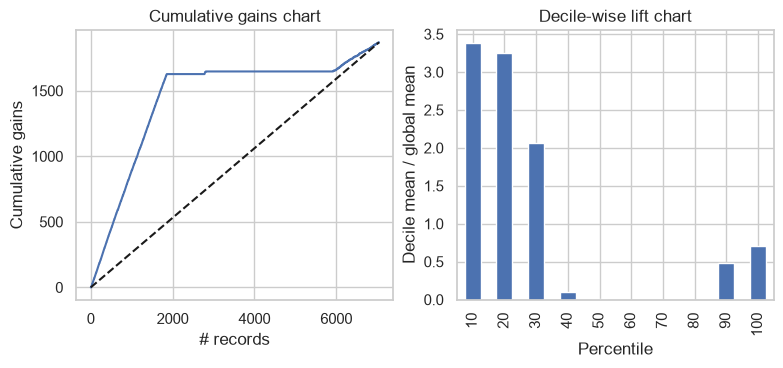

In [ ]:
# cumulative gains and lift chart

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(9, 3.5))
ax = mlba.gainsChart(df2a3, ranking='rf_pred', actual='Churn Value', type='regression',
                      ax=axes[0])
ax.set_ylabel('Cumulative gains')
ax.ticklabel_format(style='plain')

mlba.liftChart(df2a3, ranking='rf_pred', actual='Churn Value', ax=axes[1], labelBars=False)

# Shmueli, G., Bruce, P. C., Gedeck, P., & Patel, N. R. (2025). Machine learning for business analytics (2nd ed.).
# Wiley-Blackwell. https://bookshelf.vitalsource.com/books/9781394286805

The cumulative gains and lift charts, in addition to the correlation data, demonstrates the importance and utility of the random forests model. The cumulative gains charts show that within approximately the first 2000 records, there are approximately 1600 churners. Moving from 2000 to 6000 records, the number of churners does not change. However, the number of churners increases again moving from 6000 to 7000 records.

The lift chart reflects those changes in number of churners. It also, shows that the top 20% of these customers will increase the churn rate at least 3 fold. The 30th percentile doubles the churn rate. The small gains in the last 10th percentile does not yield a lift equivalent to the baseline churn rate. Therefore the top 30% of customers should be the focus of intervening methods.

In [ ]:
# create data frame with the percentile label

df2a4 = df2a2.copy()

df2a4['Percentile Group'] = pd.qcut(
    df2a4['rf_pred'].rank(method='first', ascending=False),
    q=10,
    labels=False
) + 1

In [ ]:
# churn rate per percentile group

summary = df2a4.groupby('Percentile Group').agg(
    Customers=('Churn Value', 'size'),
    Actual_Churners=('Churn Value', 'sum'),
    Churn_Rate=('Churn Value', 'mean')
)

summary['Churn_Rate'] *= 100

print(summary)

                  Customers  Actual_Churners  Churn_Rate
Percentile Group                                        
1                       705              705     100.000
2                       704              704     100.000
3                       704              231      32.812
4                       704               26       3.693
5                       705              203      28.794
6                       704                0       0.000
7                       704                0       0.000
8                       704                0       0.000
9                       704                0       0.000
10                      705                0       0.000


In [ ]:
# looking at the features of each percentile group

selected_cols = [
    'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup',
    'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
    'Payment Method', 'Monthly Charges', 'Total Charges'
]

categorical_summary = pd.concat(summaries, ignore_index=True)

categorical_summary = categorical_summary[
    ['Percentile Group', 'Feature', 'Category', 'Percentage']
]

top3_summary = categorical_summary[
    categorical_summary['Percentile Group'].isin(range(1, 11))
    & categorical_summary['Feature'].isin(selected_cols)
]

top3_wide = top3_summary.pivot_table(
    index=['Feature', 'Category'],
    columns='Percentile Group',
    values='Percentage'
).round(1)


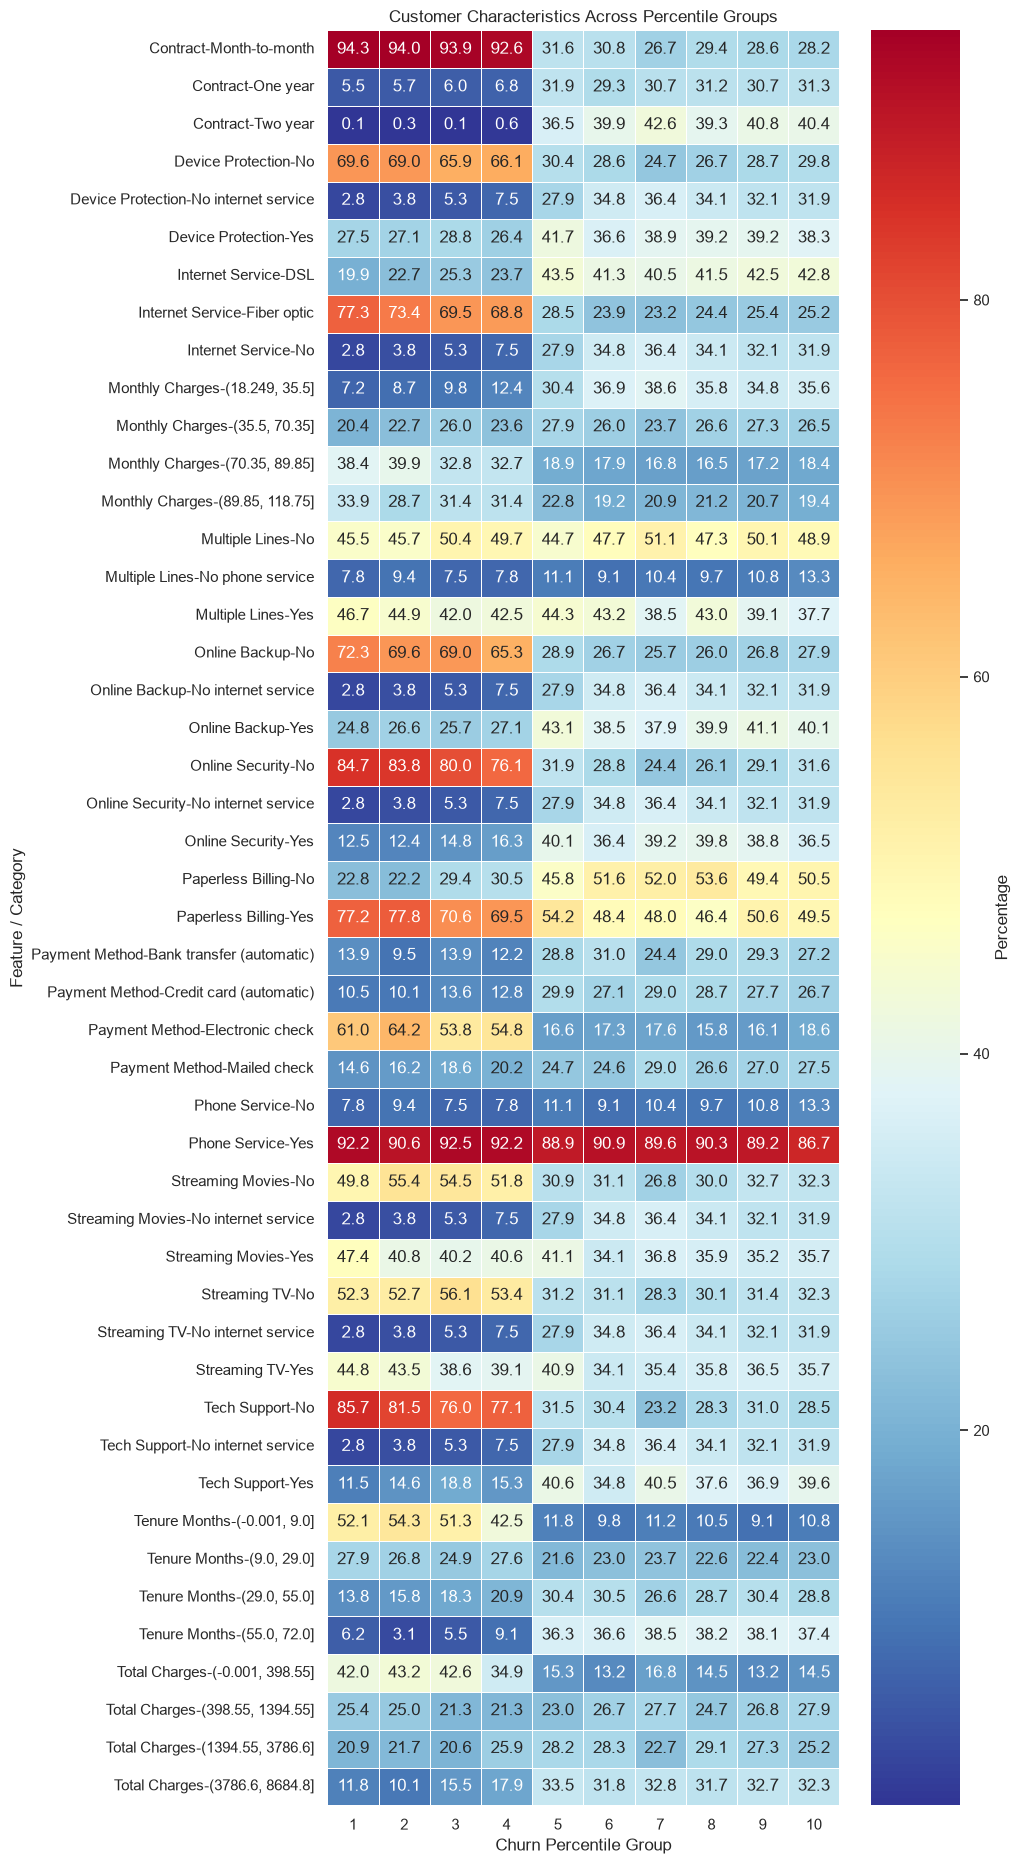

In [ ]:
# heatmap summary of percentile groups

plt.figure(figsize=(10, max(4, len(data) * 0.4)))

sns.heatmap(
    top3_wide,
    annot=True,
    fmt=".1f",
    cmap="RdYlBu_r",
    linewidths=0.5,
    cbar_kws={"label": "Percentage"}
)

plt.title(f"Customer Characteristics Across Percentile Groups")
plt.xlabel("Churn Percentile Group")
plt.ylabel("Feature / Category")
plt.tight_layout()
plt.show()

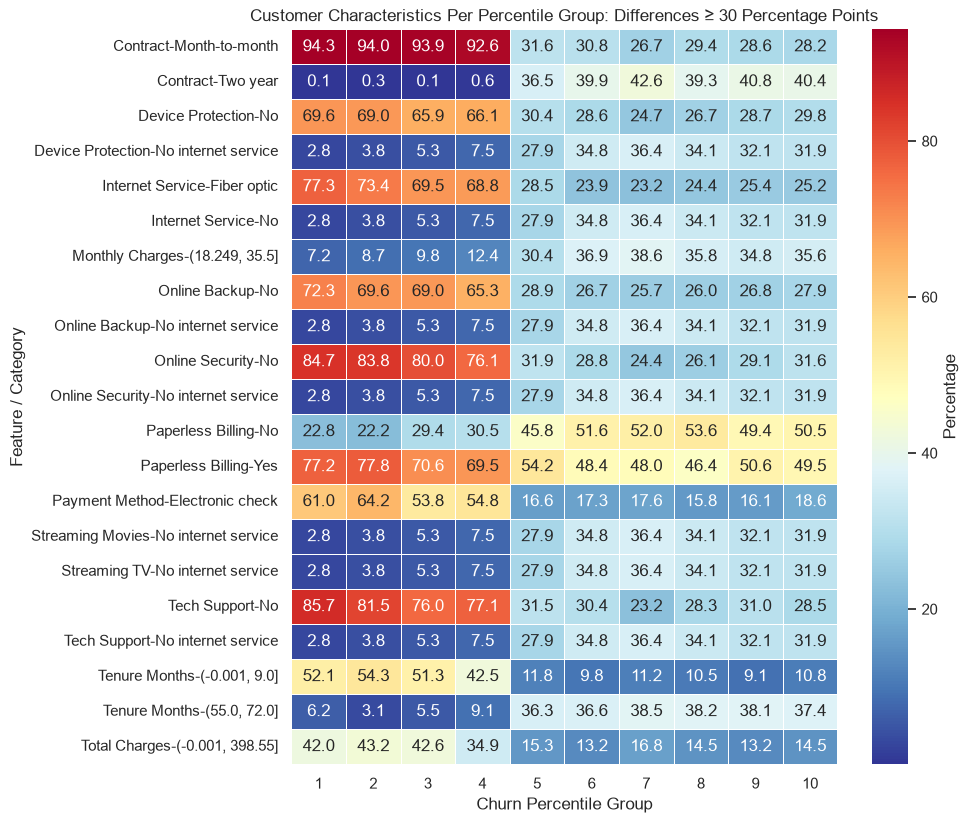

In [ ]:
# truncated version of the heat map looking only at the features with large differences between the max and min of each row

# Difference between highest and lowest percentile-group values per row
row_diff = top3_wide.max(axis=1) - top3_wide.min(axis=1)

# Highlight rows where the difference is at least 20 percentage points
threshold = 30

large_diff = row_diff >= threshold

# Keep rows with large differences
heatmap_data = top3_wide.loc[large_diff]

plt.figure(figsize=(10, max(4, len(heatmap_data) * 0.4)))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="RdYlBu_r",
    linewidths=0.5,
    cbar_kws={"label": "Percentage"}
)

plt.title(f"Customer Characteristics Per Percentile Group: Differences ≥ {threshold} Percentage Points")
plt.xlabel("Churn Percentile Group")
plt.ylabel("Feature / Category")
plt.tight_layout()
plt.show()

In diving deeper, the proportions of each feature with each percentile group were shown in a heat map. The rows above are groups for which there is a difference of at least 30% between the maximum and minimum values. Each of these groups could prove to be instrumental in finding high-risk churners.

# Discussion

After selecting the Random Forests model, the subsequent analysis took a complex analytical path, particularly when trying to identify larger customer types. First, a side-by-side comparison of the actual and predicted churn rates showed that the model consistently overpredicted churn, with the magnitude of the overprediction increasing alongside the churn count. This meant that the predicted values captured the churn trends, but the counts and rates were not accurate. While the Random Forests predictions provided an avenue for trying to find customer types with higher propensities to churn, there could have been more strategic options.

The first option explored was clustering the modeling data set via K-Prototype because it could accommodate a combination of categorical and numerical data. Overall, this endeavor was fruitless. A first pass was conducted using the entire data set without the actual or predicted churn data. Two models were developed in parallel because the cost analysis favored k = 2, while the silhouette score analysis favored k = 4 clusters, indicating slightly better cluster separation. Unfortunately, a purity analysis revealed nearly identical overall homogeneity levels in both models, meaning neither was superior to the other. In addition, no cluster exhibited a churn rate significantly higher than another. Further investigation into the clusters produced by each model showed that the cluster profiles offered little discriminatory power.

Upon closer inspection, the demographic categories showed very similar distributions across the clusters within and between the models. Therefore, a second pass of the K-Prototype model was performed with the same data set excluding demographic data, such as the gender or age-specific columns. The assumption was that eliminating information held fairly constant in both models might lead to greater separation of the clusters. However, the resulting clusters were nearly identical to those in the first pass. In fact, the cost analysis favored k = 2 clusters and the silhouette scores favored k = 4, again. Even more striking was that the silhouette scores were nearly identical between the two passes. This suggests that the demographic data had limited influence on the clustering results. More than that, these results suggest that clustering is unlikely to provide an effective solution without further refinement.

Despite this setback, customer segments were identified using association rules. Through experimentation with different combinations of support, antecedent itemset size, and confidence, three association rules were revealed. A smaller number of rules was preferred to simplify downstream applications. The actual and predicted churn rates of customers within these rules were 70.3% and 97.3%, respectively, in comparison to the baseline 26.5% and 39.6% churn rates. However, further investigation showed that the actual (20.9%) and predicted (32.3%) churn rates of customers outside of the association rules remained largely unchanged, meaning that the association rules only grouped a small subset of all churners. When assigning customers labels of low, medium, and high churn risk, the model identified 563 medium- and high-risk churners within the association rules but 1254 medium- and high-risk churners were not included in the association rules. In short, the association rules identified a specific subset of churners, but failed to flag a majority of churners. Unfortunately, the association rules cannot be recommended at this time, but additional data or further experimentation could lead to a solution faster than through clustering.

With these two unsuccessful modeling attempts, the analysis returned to the Random Forests model outputs. A visual inspection of the churn-related data in the rules-and-risk subgroups revealed that the Churn Scores and Random Forests-generated probabilities appeared to trend with the actual churn rates. In fact, when grouping all customers based on Churn Score, those with scores greater than 70 yielded a churn rate of 64.7% and those with scores less than or equal to 70 yielded a churn rate of 6.6%. When grouping the customers based on the Random Forests probability, customers with predicted churn probabilities above 0.6 had a 65.2% churn rate, compared with 8.4% among those with probabilities of 0.6 or lower. This information suggests that either filtering process groups the majority of churners very efficiently. Thus, one solution to finding customer types with high-churn correlations would be through the Random Forests probabilities.

Despite the earlier concerns about overprediction, the Random Forests model provides a straightforward approach to targeting high-risk customers. Although its predicted churn rates were higher than the observed rates, the model's ability to rank customers by relative churn risk remained useful for segmentation. The lift chart showed that the 10th and 20th percentile of customers ranked by predicted churn risk exhibited a churn rate more than three times that of the baseline and customers in the 30th percentile have a churn rate double that of the baseline. The cumulative gains chart showed that most observed churners were captured within the top 30% of customers ranked by predicted risk, with additional churners captured in the final 10%. Taking this a step further, the feature groups were analyzed across all ten percentile groups in a heat map, highlighting the proportion of feature group events within a percentile group. The month-to-month contract group immediately stands out because of its approximately 90% prevalence within the high-risk groups, compared with only 0–5% for one- and two-year contracts. Conversely, longer-term contracts account for approximately 30–40% of events in the low-risk groups. These findings suggest that contract type is an important characteristic associated with churn risk. The Business Strategy team could investigate incentives encouraging high-risk, month-to-month customers to transition to one- or two-year contracts. Although the analysis does not establish that changing contract type would reduce churn, this approach represents a promising retention strategy to evaluate. This heat map provides the Business Strategy team with a practical guide to find additional approaches to discouraging churn in high-risk customers.


# Conclusion

In conclusion, the Random Forests model is a valuable approach for HorizonTel Communications to identify and address customer churn risk. Comparisons with logistic regression and k-nearest neighbor models showed that Random Forests was more effective at distinguishing churners from non-churners. Although the model tended to overpredict churn, it remained effective at identifying high-risk customers. When customers were ranked by predicted churn risk, the model concentrated the majority of observed churners within the top 30%. Furthermore, the analysis highlighted key characteristics distinguishing high- and low-risk customer groups. Taken together, these findings help HorizonTel prioritize high-risk customers for retention efforts and identify customer characteristics that could inform targeted retention strategies and business practices.

# References  

Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical). Towards Data Science. https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

Chatgpt. (n.d.). ChatGPT. https://chatgpt.com/

Shmueli, G., Bruce, P. C., Gedeck, P., & Patel, N. R. (2025). Machine learning for business analytics (2nd ed.). Wiley-Blackwell. https://bookshelf.vitalsource.com/books/9781394286805

Staff, C. (2022, December 2). Silhouette coefficient for k-modes and k-prototypes clustering. Coding Infinite. https://codinginfinite.com/silhouette-coefficient-for-k-modes-and-k-prototypes-clustering/

TanKY. (n.d.). Telco customer churn: IBM dataset. Kaggle. Retrieved https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset?select=Telco_customer_churn.xlsx

Telco customer churn (11.1.3+). (n.d.). Retrieved October 18, 2026, from https://community.ibm.com/community/user/businessanalytics/blogs/steven-macko/2019/07/11/telco-customer-churn-1113


